## Oresund

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import mikeio
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import modelskill as ms
import torch

# dataset helper
from helper import get_altimetry_obs, get_wl_point_obs
from helper import plot_shred_reconstruction, extract_water_level_measurements

import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent.parent))

# Importing modules from src
from src.datamanager import DataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.mSHRED.mSHRED import mSHRED
from src.utils import plot_training_curves, evaluate_model

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Load Data and Measurement

In [3]:
# OPEN FOLDERS
dfs_fldr = "datasets/output/Area.dfsu"
msh_fldr = "datasets/input/mesh_EMOD.mesh"
obs_fldr  = "datasets/observations/"
msh = mikeio.open(msh_fldr)
dfs = mikeio.open(dfs_fldr)
geom = dfs.geometry

ds = dfs.read(time = slice("2020-01-01", "2023-12-30"))

# sensor coverage
alllist = get_wl_point_obs()

# For sparse data simulation
hf = ["Drogden", "Klagshamn", "Dragor", "Barseback"]
# availabilities 97-50-98-50
alllist = [s for s in alllist if s.name in hf]

# Extract the values and convert to torch tensors

measurements = extract_water_level_measurements(alllist, ds_time=ds.time, obs_fldr=obs_fldr)
measurements = torch.as_tensor(measurements, dtype=torch.float32)
print("IN:\nMeasurements shape:", measurements.shape)

# Build a single mask for nodes that are valid in all output fields
surface = ds["Surface elevation"].values
u_velocity = ds["U velocity"].values
v_velocity = ds["V velocity"].values
valid_nodes = np.isfinite(surface).all(axis=0) & np.isfinite(u_velocity).all(axis=0) & np.isfinite(v_velocity).all(axis=0)

# outputs
H = torch.from_numpy(surface[:, valid_nodes].astype(np.float32, copy=False))
U = torch.from_numpy(u_velocity[:, valid_nodes].astype(np.float32, copy=False))
V = torch.from_numpy(v_velocity[:, valid_nodes].astype(np.float32, copy=False))

# print the shape of the arrays
print("OUT:\nH shape:", H.shape)
print("U shape:", U.shape)
print("V shape:", V.shape)

# free memory
del surface, u_velocity, v_velocity, valid_nodes, dfs

IN:
Measurements shape: torch.Size([70080, 4])
OUT:
H shape: torch.Size([70080, 3320])
U shape: torch.Size([70080, 3320])
V shape: torch.Size([70080, 3320])


In [4]:
ERRORS = []

# DataManager
LAGS = 24

TRAIN_SIZE = 0.8        # percentage of data used for training 
VAL_SIZE = 0.1          # percentage of data used for validation
TEST_SIZE = 0.1         # percentage of data used for testing

COMPRESS_H = 12         # modes kept for H (surface elevation)
COMPRESS_U = 40         # modes kept for U (U velocity)
COMPRESS_V = 68         # modes kept for V (V velocity)

# Training
OPTIMIZER = "AdamW"     # optimizer to use
LEARNING_RATE = 5e-4    # learning rate for training
NUM_EPOCHS = 200        # maximum number of epochs for training
LR_SCHEDULER = "CosineAnnealingLR"      # learning rate scheduler to use
SCHEDULER_STEP_SIZE = NUM_EPOCHS        # step size for learning rate scheduler (if applicable)

BATCH_SIZE = 32         # batch size for training
PATIENCE = 40           # number of epochs with no improvement on validation loss before stopping training
VERBOSE_TRAIN = True

# Architecture
ENCODER_DEPTH = 2              # number of encoder layers
HIDDEN_SIZE = 32                # hidden size for encoder and decoder layers
N_HEADS = 4                     # number of attention heads (if using a transformer-based architecture)
DIM_FEEDFORWARD = 48            # dimension of feedforward network in transformer (if using a transformer-based architecture)
DECODER = "cnn"                 # type of decoder to use (mpl or cnn)   
DECODER_HIDDEN_SIZES = [64]     # hidden sizes for decoder layers 
DROPOUT = 0.0                   # dropout rate for encoder and decoder layers
MASKING_TYPE = "mask_data"      # type of masking to apply to inputs during training (mask_data, mask_data_random, etc.)

## (T.1.A): Median imputer

In [5]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS_H, measurements=measurements, imputer="median")
manager.add_data(U, id="U velocity", compress=COMPRESS_U)
manager.add_data(V, id="V velocity", compress=COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True)

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([56064, 24, 4]) -> torch.Size([56064, 120])
Val:	 torch.Size([7008, 24, 4]) -> torch.Size([7008, 120])
Test:	 torch.Size([7008, 24, 4]) -> torch.Size([7008, 120])

Input shape for the model: 4
Output shape for the model: 120


Starting training...


Training:  48%|████▊     | 95/200 [09:24<10:23,  5.94s/it, Train Loss=0.00360, Val Loss=0.00354, Patience=39, Best Val Loss=0.00345, LR=2.66e-04]

Early stopping at epoch 96
Training completed with best validation loss: 0.0035


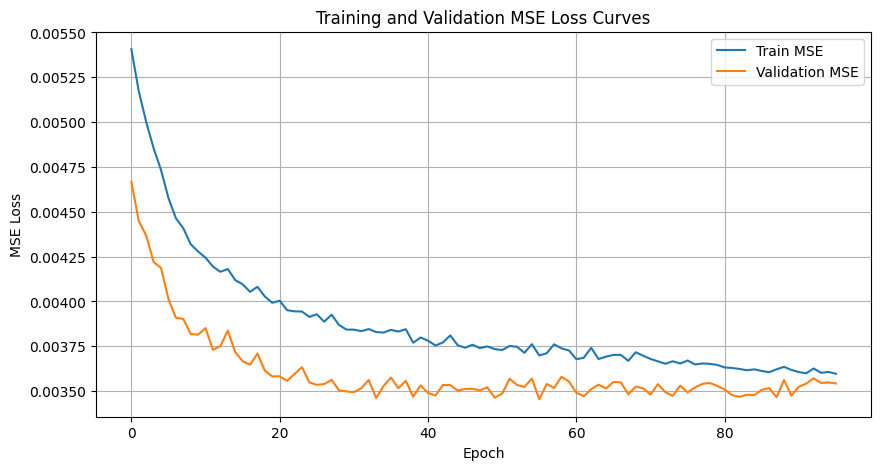

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003699,0.003455,0.00477,0.14125,0.138557,0.155077


In [6]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.1.A): median imputation for missing sensors"
 )

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/ORESUND/outputs/shred_(T.1.A)_median_imputation.png


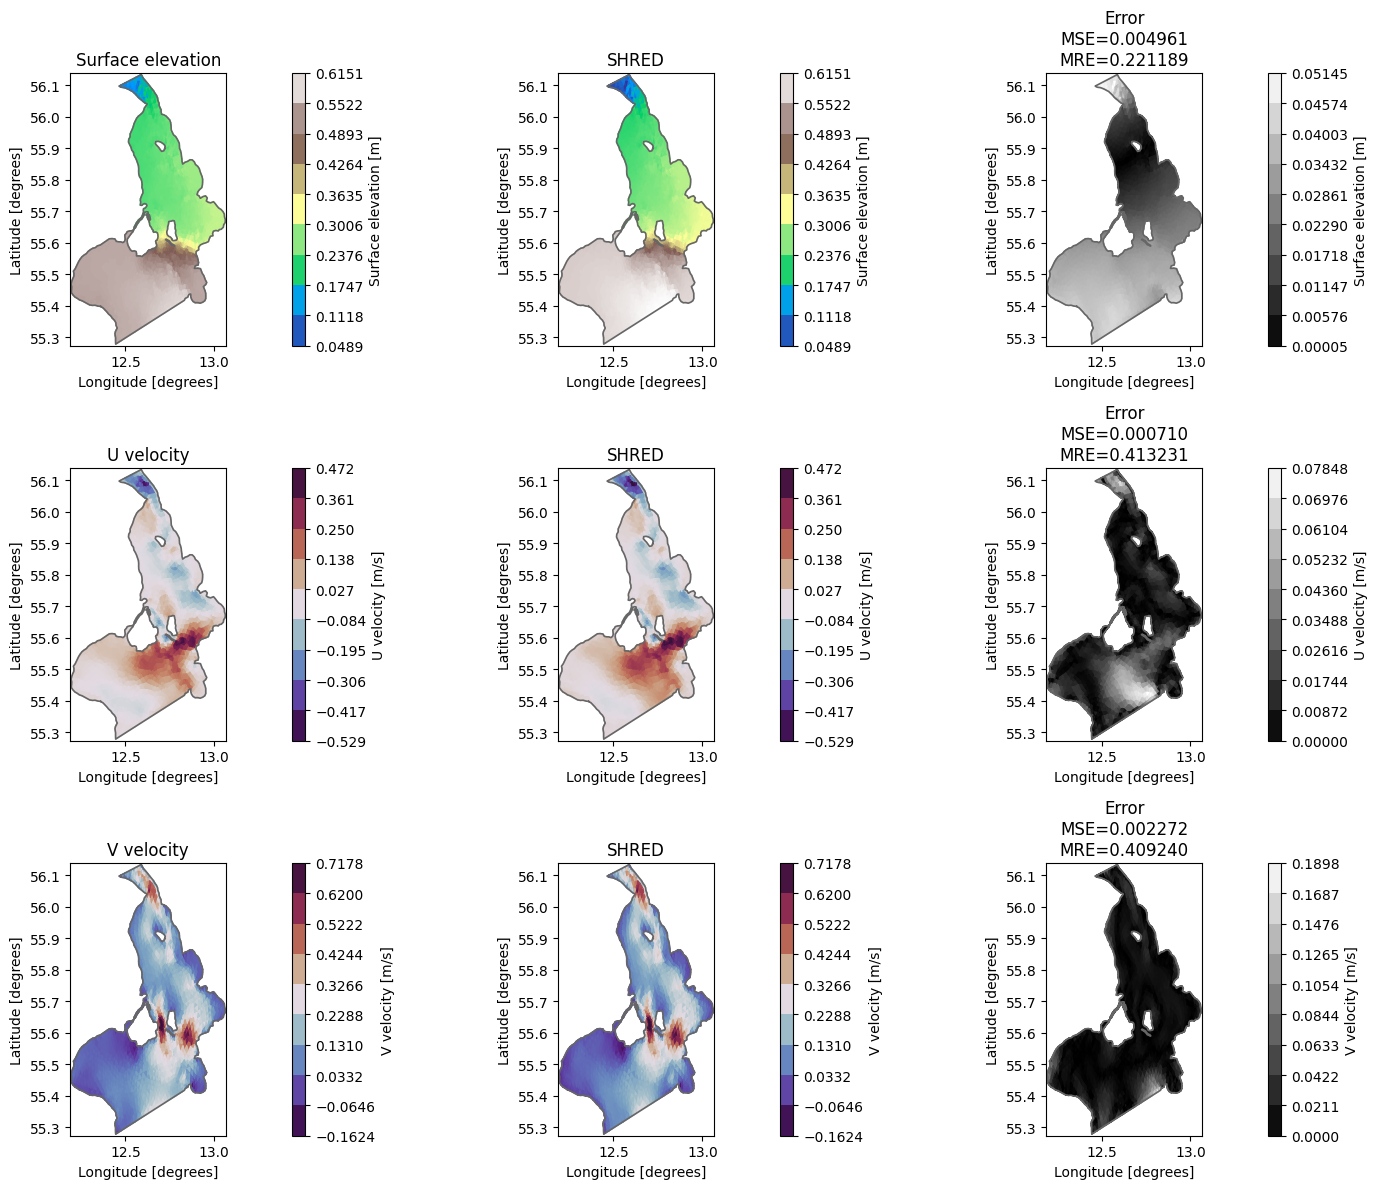

In [7]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.1.A)_median_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager, train_dataset, val_dataset, test_dataset, model_args, train_errors, valid_errors, test_error, nn_input_shape, nn_output_shape

## (T.1.B): Mean imputer

In [8]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS_H, measurements=measurements, imputer="mean")
manager.add_data(U, id="U velocity", compress=COMPRESS_U)
manager.add_data(V, id="V velocity", compress=COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True)

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([56064, 24, 4]) -> torch.Size([56064, 120])
Val:	 torch.Size([7008, 24, 4]) -> torch.Size([7008, 120])
Test:	 torch.Size([7008, 24, 4]) -> torch.Size([7008, 120])

Input shape for the model: 4
Output shape for the model: 120


Starting training...


Training:  64%|██████▍   | 128/200 [11:20<06:22,  5.31s/it, Train Loss=0.00353, Val Loss=0.00357, Patience=39, Best Val Loss=0.00349, LR=1.40e-04]

Early stopping at epoch 129
Training completed with best validation loss: 0.0035


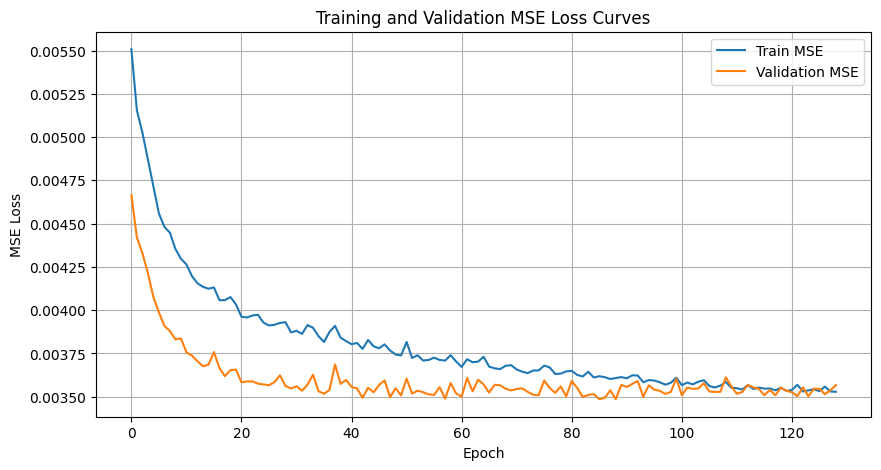

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003699,0.003455,0.004770,0.141250,0.138557,0.155077
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003608,0.003485,0.004753,0.139722,0.138935,0.154002


In [9]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.1.B): mean imputation for missing sensors"
 )

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/ORESUND/outputs/shred_(T.1.B)_mean_imputation.png


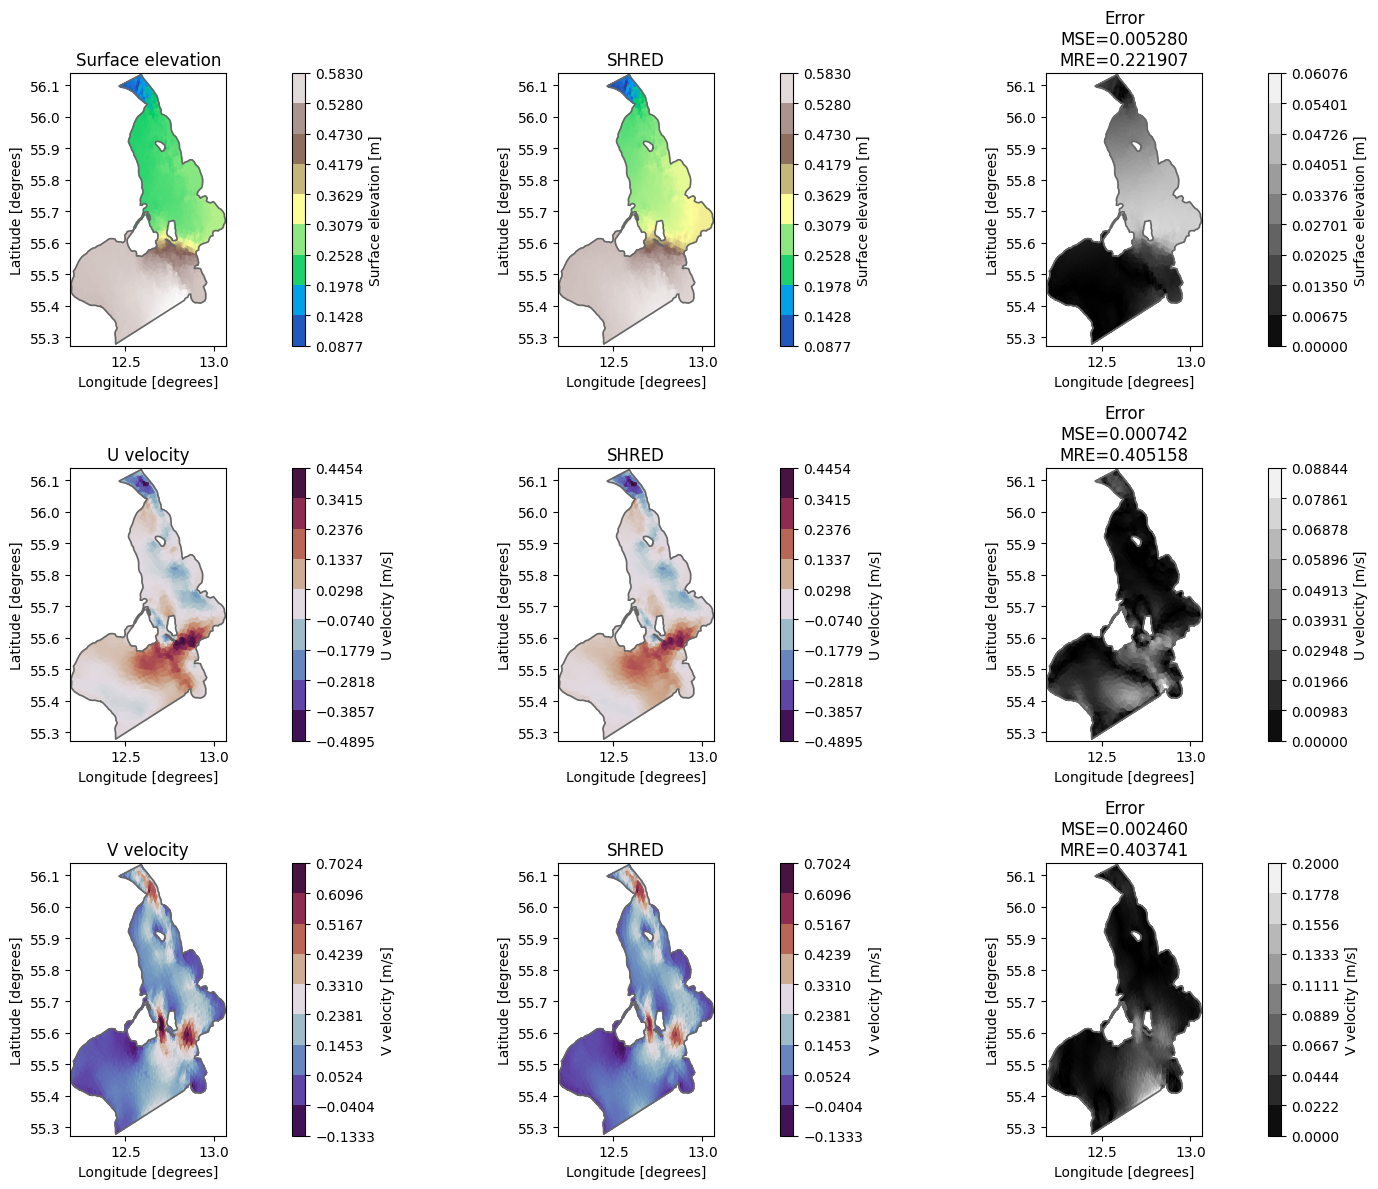

In [10]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.1.B)_mean_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager, train_dataset, val_dataset, test_dataset, model_args, train_errors, valid_errors, test_error, nn_input_shape, nn_output_shape

## (T.1.C): Last value imputer

In [11]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS_H, measurements=measurements, imputer="last_value")
manager.add_data(U, id="U velocity", compress=COMPRESS_U)
manager.add_data(V, id="V velocity", compress=COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True)

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([56064, 24, 4]) -> torch.Size([56064, 120])
Val:	 torch.Size([7008, 24, 4]) -> torch.Size([7008, 120])
Test:	 torch.Size([7008, 24, 4]) -> torch.Size([7008, 120])

Input shape for the model: 4
Output shape for the model: 120


Starting training...


Training:  39%|███▉      | 78/200 [06:53<10:47,  5.31s/it, Train Loss=0.00353, Val Loss=0.00351, Patience=39, Best Val Loss=0.00343, LR=3.31e-04]

Early stopping at epoch 79
Training completed with best validation loss: 0.0034


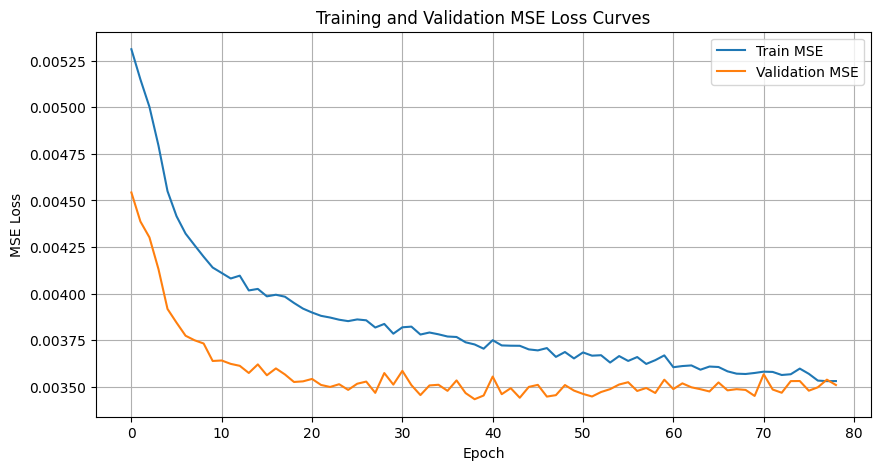

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003699,0.003455,0.004770,0.141250,0.138557,0.155077
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003608,0.003485,0.004753,0.139722,0.138935,0.154002
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003727,0.003432,0.004701,0.141552,0.138023,0.153497


In [12]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.1.C): last-value imputation for missing sensors"
 )

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/ORESUND/outputs/shred_(T.1.C)_last_value_imputation.png


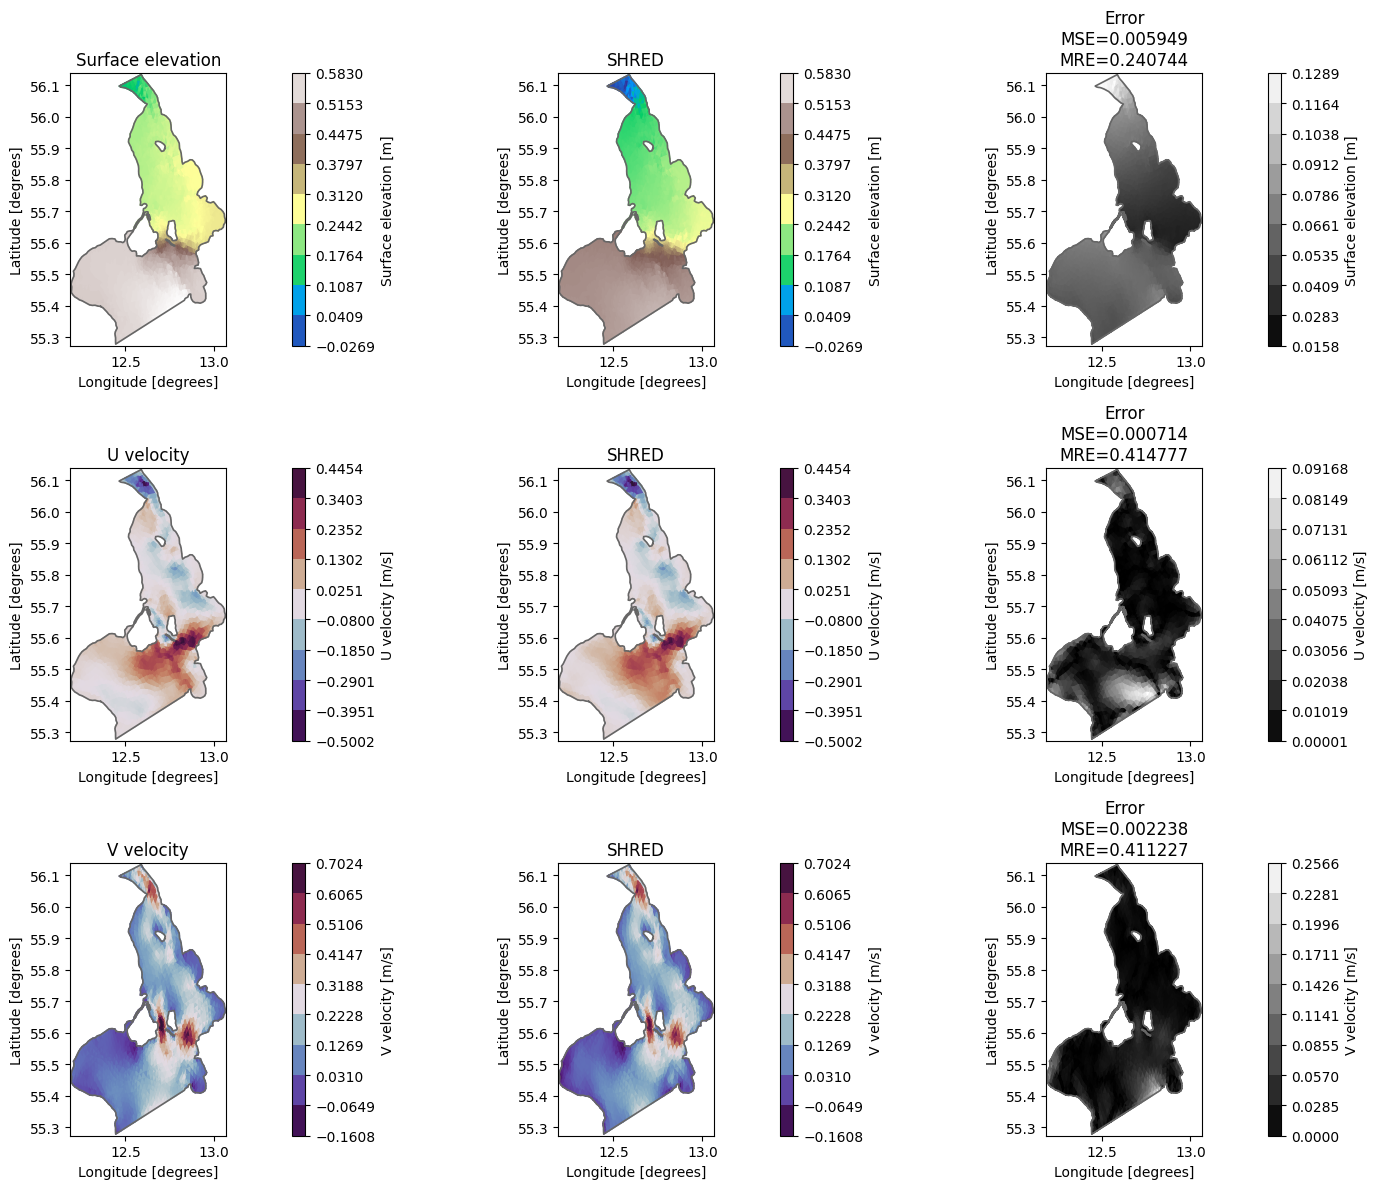

In [13]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.1.C)_last_value_imputation")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager, train_dataset, val_dataset, test_dataset, model_args, train_errors, valid_errors, test_error, nn_input_shape, nn_output_shape

## (T.2.A) GRUD

In [14]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS_H, measurements=measurements)
manager.add_data(U, id="U velocity", compress=COMPRESS_U)
manager.add_data(V, id="V velocity", compress=COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset, X_mean = manager.prepare(verbose=True, masking_type="grud")

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[-1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([56064, 4, 24, 4]) -> torch.Size([56064, 120])
Val:	 torch.Size([7008, 4, 24, 4]) -> torch.Size([7008, 120])
Test:	 torch.Size([7008, 4, 24, 4]) -> torch.Size([7008, 120])

Input shape for the model: 4
Output shape for the model: 120


Starting training...


Training:  74%|███████▎  | 147/200 [25:21<09:08, 10.35s/it, Train Loss=0.00372, Val Loss=0.00346, Patience=39, Best Val Loss=0.00345, LR=7.89e-05]

Early stopping at epoch 148
Training completed with best validation loss: 0.0035


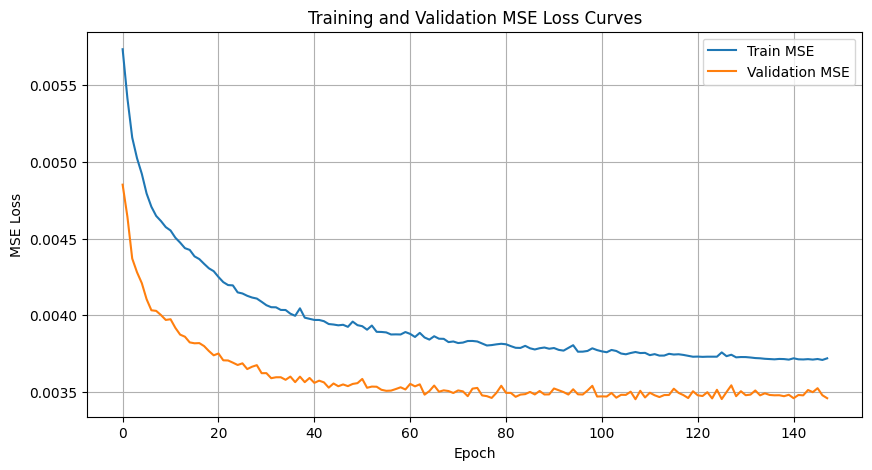

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003699,0.003455,0.004770,0.141250,0.138557,0.155077
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003608,0.003485,0.004753,0.139722,0.138935,0.154002
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003727,0.003432,0.004701,0.141552,0.138023,0.153497
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.003760,0.003452,0.004753,0.142187,0.138509,0.155241


In [15]:
# GRUD TRAINING
model_args = dict(
    # Encoder
    encoder="grud", input_size=nn_input_shape, hidden_size=HIDDEN_SIZE, X_mean=X_mean,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): GRUD+{DECODER}", type="(T.2.A): GRUD"
 )

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/ORESUND/outputs/shred_(T.2.A)_GRUD.png


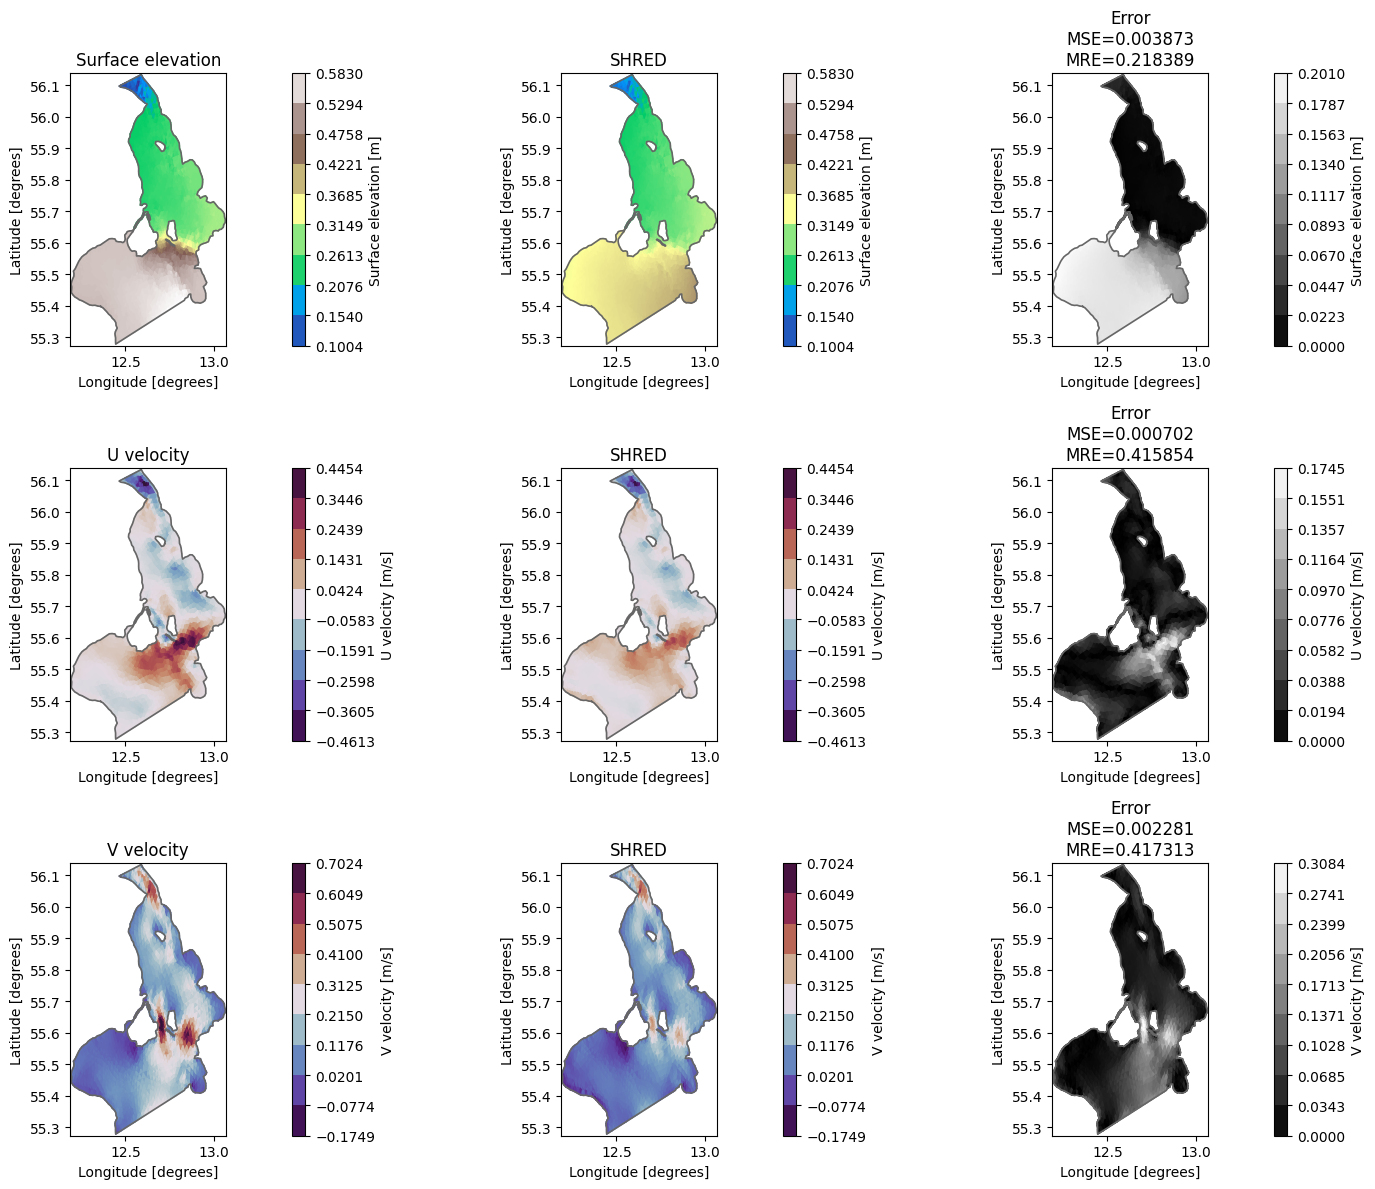

In [16]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_grud, ds_error_grud = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.2.A)_GRUD")

del engine, test_reconstruction, ds_grud, ds_error_grud, mshred, model_args, train_errors, valid_errors, test_error

## (T.2.B): Attn-GRUD

Starting training...


Training:  80%|███████▉  | 159/200 [43:55<11:19, 16.57s/it, Train Loss=0.00368, Val Loss=0.00353, Patience=39, Best Val Loss=0.00351, LR=4.77e-05]

Early stopping at epoch 160
Training completed with best validation loss: 0.0035


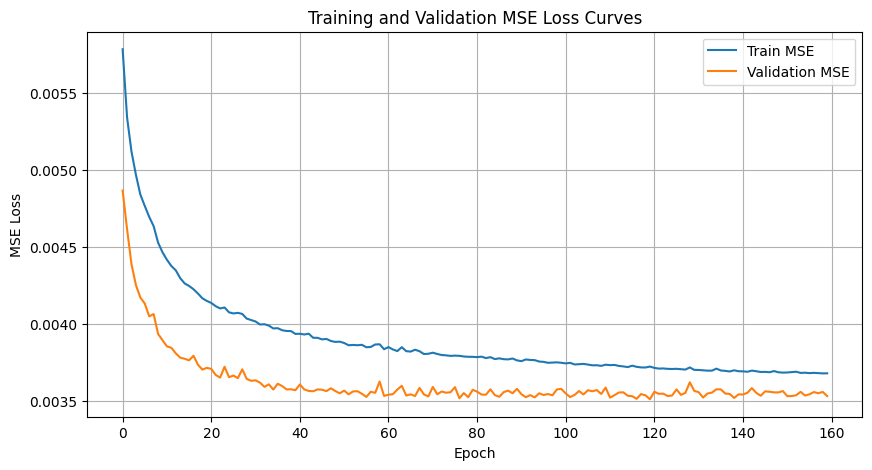

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003699,0.003455,0.004770,0.141250,0.138557,0.155077
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003608,0.003485,0.004753,0.139722,0.138935,0.154002
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003727,0.003432,0.004701,0.141552,0.138023,0.153497
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.003760,0.003452,0.004753,0.142187,0.138509,0.155241
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.003722,0.003510,0.004759,0.141516,0.139357,0.155506


In [17]:
# Attn-GRUD TRAINING
model_args = dict(
    # Encoder
    encoder="att_grud", input_size=nn_input_shape, hidden_size=HIDDEN_SIZE, X_mean=X_mean,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): Attn-GRUD+{DECODER}", type="(T.2.B): Attn-GRUD"
 )

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/ORESUND/outputs/shred_(T.2.B)_Attn-GRUD.png


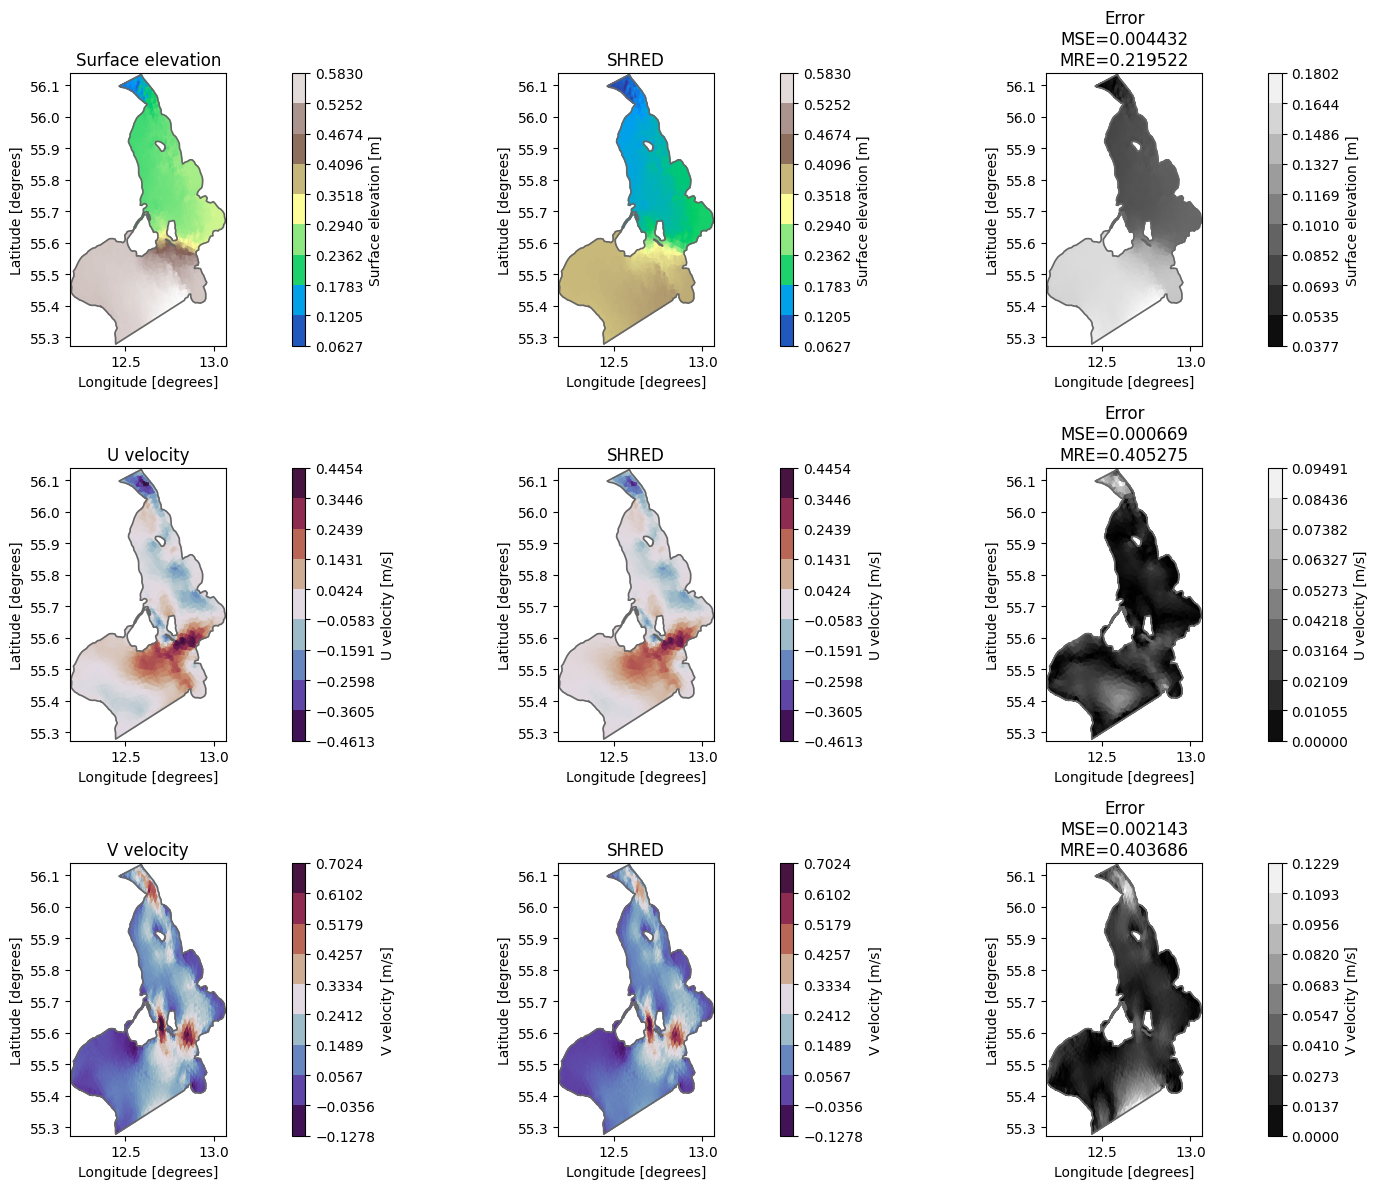

In [18]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_grud, ds_error_grud = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.2.B)_Attn-GRUD")

del engine, test_reconstruction, ds_grud, ds_error_grud, mshred, manager, train_dataset, val_dataset, test_dataset, model_args, train_errors, valid_errors, test_error, nn_input_shape, nn_output_shape, X_mean

## (T.3.A): Masking

In [19]:
# Data manager
manager = DataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS_H, measurements=measurements)
manager.add_data(U, id="U velocity", compress=COMPRESS_U)
manager.add_data(V, id="V velocity", compress=COMPRESS_V)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True, masking_type=MASKING_TYPE)

# network input and output shapes
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)


Datasets: ['Surface elevation', 'U velocity', 'V velocity']

Number of nan values in sensor measurements after masking: 72656

Data shapes after preparation:
Train:	 torch.Size([56064, 24, 4]) -> torch.Size([56064, 120])
Val:	 torch.Size([7008, 24, 4]) -> torch.Size([7008, 120])
Test:	 torch.Size([7008, 24, 4]) -> torch.Size([7008, 120])

Input shape for the model: 4
Output shape for the model: 120


Starting training...


Training:  58%|█████▊    | 116/200 [11:21<08:13,  5.88s/it, Train Loss=0.00346, Val Loss=0.00347, Patience=39, Best Val Loss=0.00342, LR=1.84e-04]

Early stopping at epoch 117
Training completed with best validation loss: 0.0034


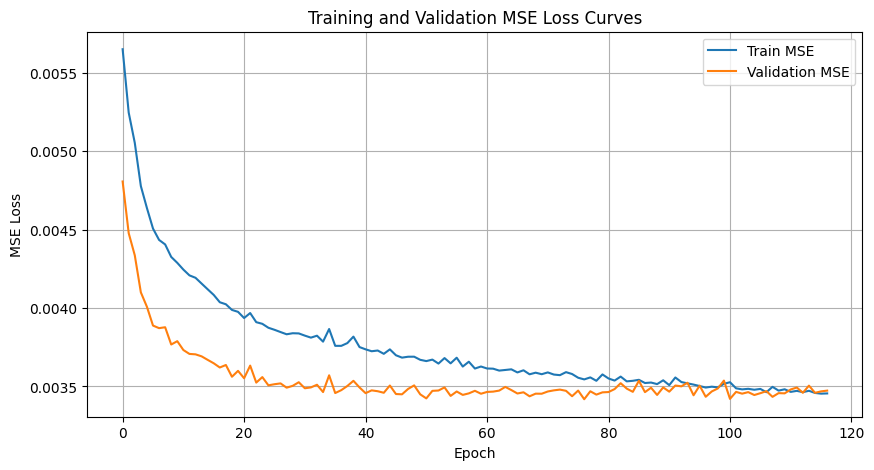

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003699,0.003455,0.004770,0.141250,0.138557,0.155077
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003608,0.003485,0.004753,0.139722,0.138935,0.154002
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003727,0.003432,0.004701,0.141552,0.138023,0.153497
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.003760,0.003452,0.004753,0.142187,0.138509,0.155241
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.003722,0.003510,0.004759,0.141516,0.139357,0.155506
5,(mSHRED): TR+cnn,(T.3.A): masking,0.003545,0.003419,0.004736,0.138358,0.137742,0.153346


In [20]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.A): masking", masking_type=MASKING_TYPE
)

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/ORESUND/outputs/shred_(T.3.A)_masking.png


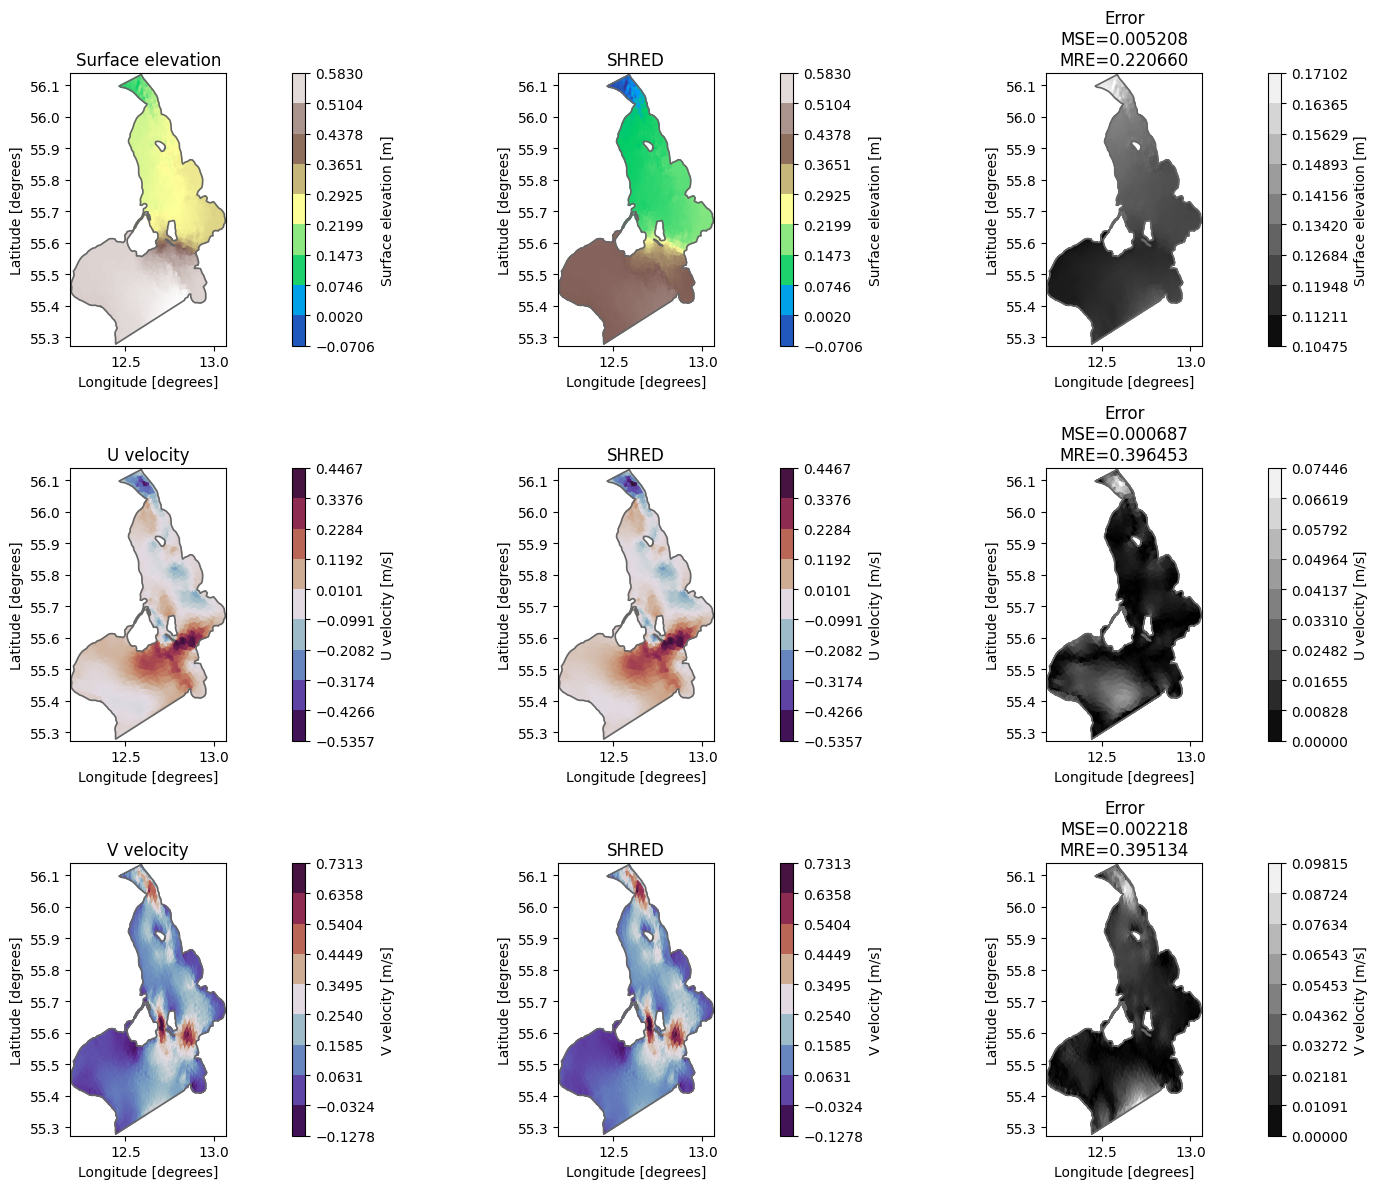

In [21]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.3.A)_masking")

del engine, test_reconstruction, ds_shred, ds_error, mshred, model_args, train_errors, valid_errors, test_error

## (T.3.B): Masking x2 channels

Starting training...


Training:  46%|████▌     | 91/200 [08:43<10:27,  5.76s/it, Train Loss=0.00354, Val Loss=0.00352, Patience=39, Best Val Loss=0.00345, LR=2.81e-04]

Early stopping at epoch 92
Training completed with best validation loss: 0.0034


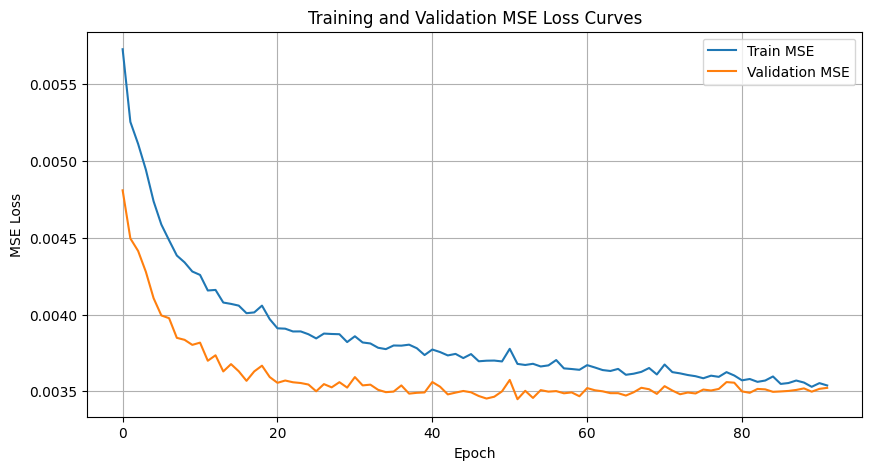

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003699,0.003455,0.004770,0.141250,0.138557,0.155077
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003608,0.003485,0.004753,0.139722,0.138935,0.154002
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003727,0.003432,0.004701,0.141552,0.138023,0.153497
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.003760,0.003452,0.004753,0.142187,0.138509,0.155241
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.003722,0.003510,0.004759,0.141516,0.139357,0.155506
5,(mSHRED): TR+cnn,(T.3.A): masking,0.003545,0.003419,0.004736,0.138358,0.137742,0.153346
6,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.003678,0.003448,0.004570,0.140781,0.138353,0.151570


In [22]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.B): masking x2 channels", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/ORESUND/outputs/shred_(T.3.B)_masking_x2_channels.png


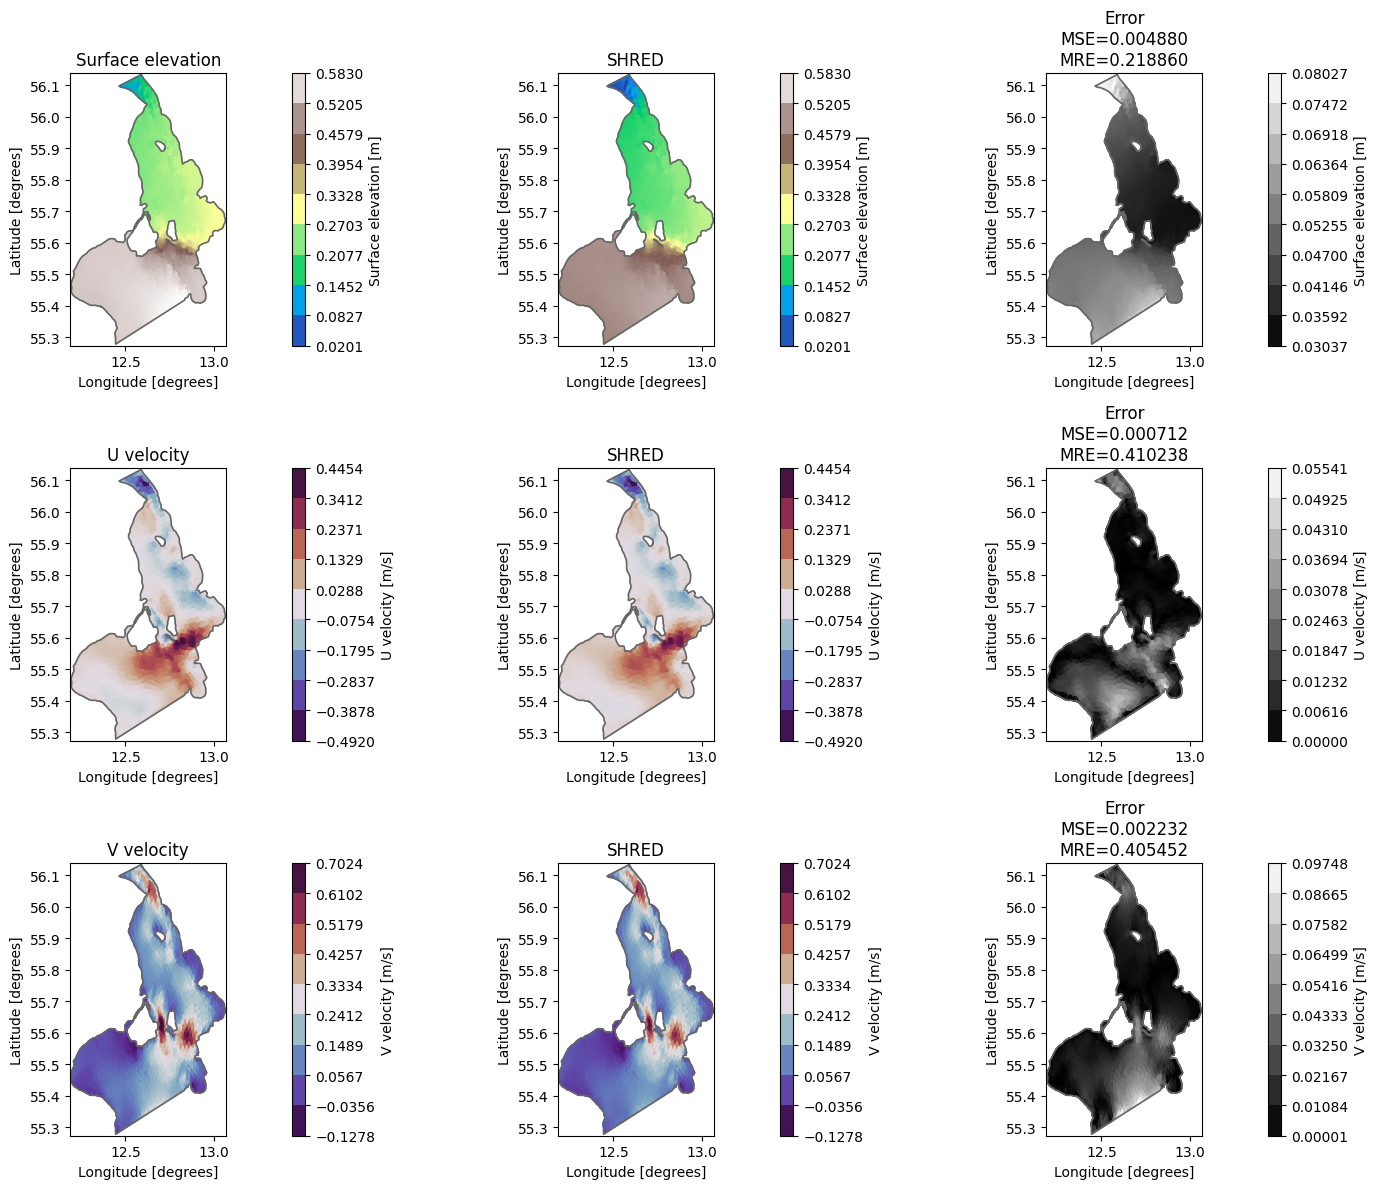

In [23]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.3.B)_masking_x2_channels")

del engine, test_reconstruction, ds_shred, ds_error, mshred, model_args, train_errors, valid_errors, test_error

## (T.3.C): Masking hidden space

Starting training...


Training:  74%|███████▍  | 148/200 [14:18<05:01,  5.80s/it, Train Loss=0.00347, Val Loss=0.00354, Patience=39, Best Val Loss=0.00343, LR=7.60e-05]

Early stopping at epoch 149
Training completed with best validation loss: 0.0034


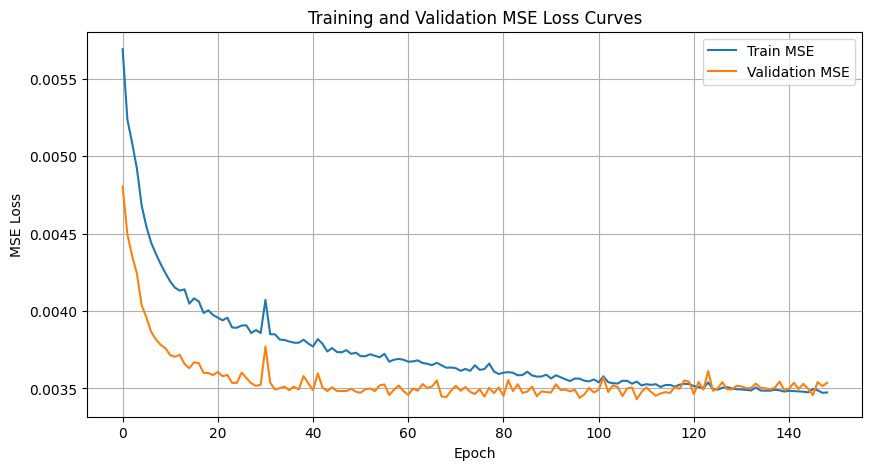

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003699,0.003455,0.004770,0.141250,0.138557,0.155077
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003608,0.003485,0.004753,0.139722,0.138935,0.154002
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003727,0.003432,0.004701,0.141552,0.138023,0.153497
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.003760,0.003452,0.004753,0.142187,0.138509,0.155241
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.003722,0.003510,0.004759,0.141516,0.139357,0.155506
5,(mSHRED): TR+cnn,(T.3.A): masking,0.003545,0.003419,0.004736,0.138358,0.137742,0.153346
6,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.003678,0.003448,0.004570,0.140781,0.138353,0.151570
7,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.003545,0.003431,0.004685,0.138363,0.137871,0.153344


In [24]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_hidden_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.C): masking hidden space", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/ORESUND/outputs/shred_(T.3.C)_masking_hidden_space.png


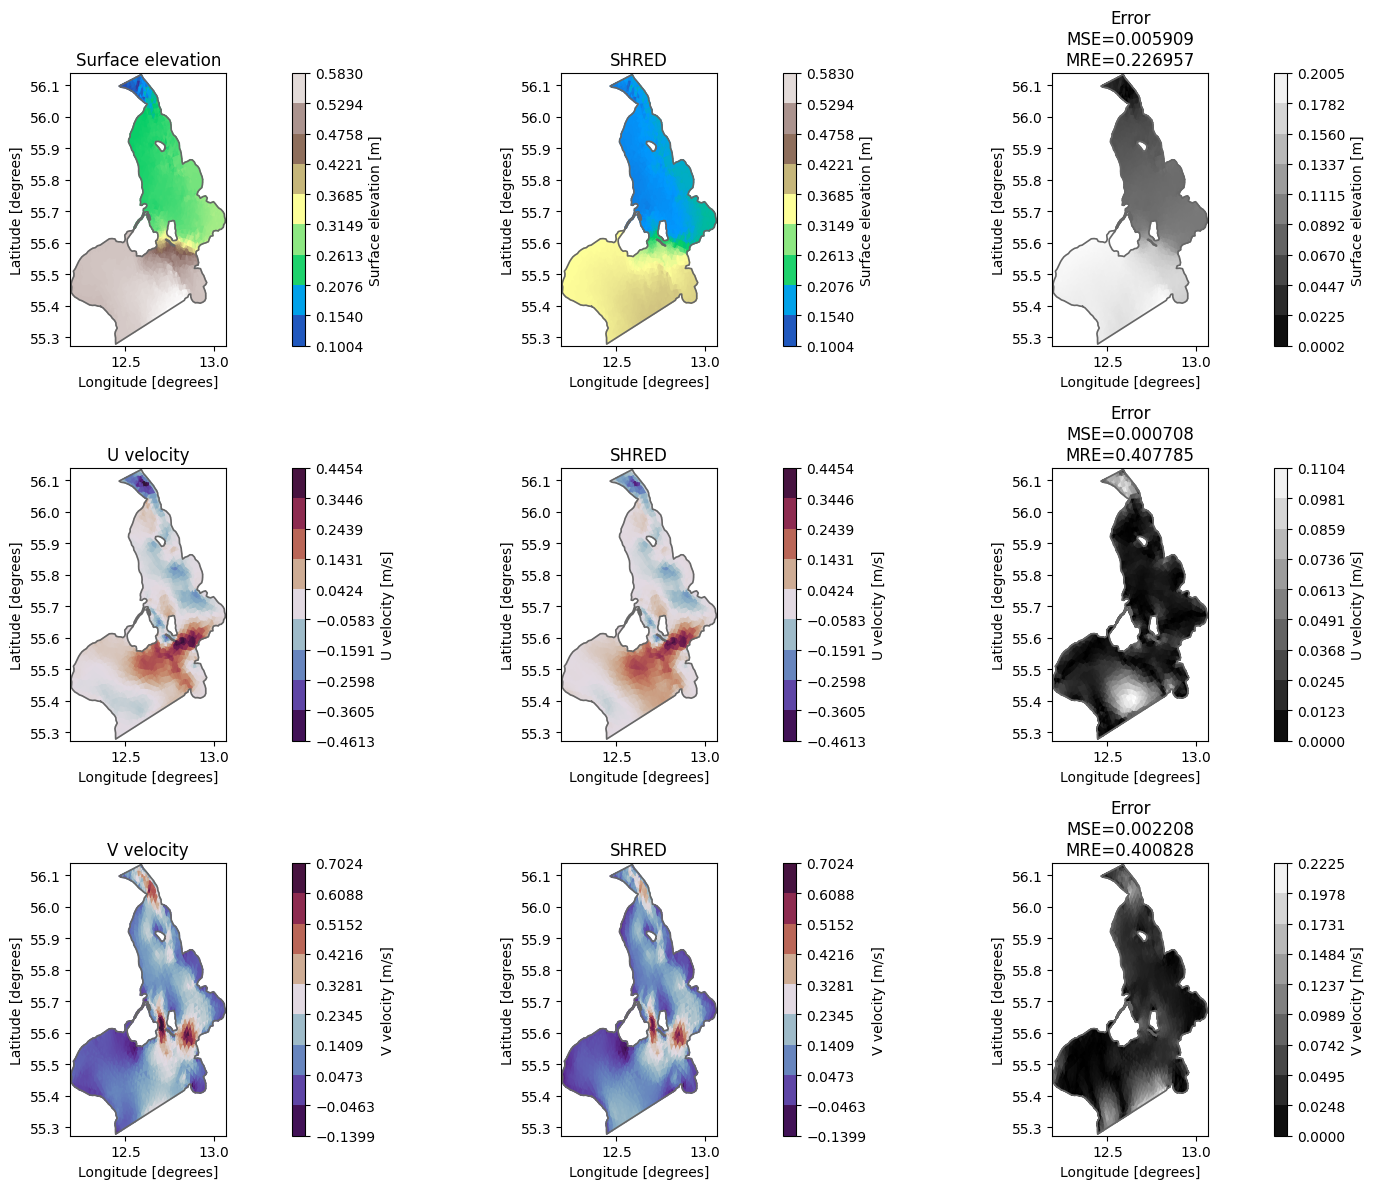

In [25]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.3.C)_masking_hidden_space")

del engine, test_reconstruction, ds_shred, ds_error, mshred, model_args, train_errors, valid_errors, test_error

## (T.3.D): Masking MHSA

Starting training...


Training:  57%|█████▋    | 114/200 [12:04<09:06,  6.36s/it, Train Loss=0.00352, Val Loss=0.00345, Patience=39, Best Val Loss=0.00342, LR=1.92e-04]

Early stopping at epoch 115
Training completed with best validation loss: 0.0034


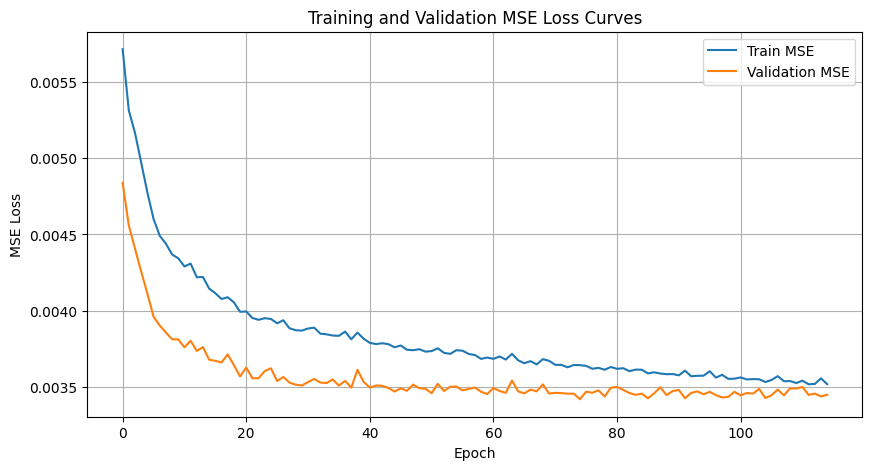

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003699,0.003455,0.004770,0.141250,0.138557,0.155077
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003608,0.003485,0.004753,0.139722,0.138935,0.154002
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003727,0.003432,0.004701,0.141552,0.138023,0.153497
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.003760,0.003452,0.004753,0.142187,0.138509,0.155241
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.003722,0.003510,0.004759,0.141516,0.139357,0.155506
5,(mSHRED): TR+cnn,(T.3.A): masking,0.003545,0.003419,0.004736,0.138358,0.137742,0.153346
6,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.003678,0.003448,0.004570,0.140781,0.138353,0.151570
7,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.003545,0.003431,0.004685,0.138363,0.137871,0.153344
8,(mSHRED): TR+cnn,(T.3.D): masking MHSA,0.003643,0.003420,0.004722,0.140272,0.137726,0.152767


In [26]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.D): masking MHSA", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/ORESUND/outputs/shred_(T.3.D)_masking_MHSA.png


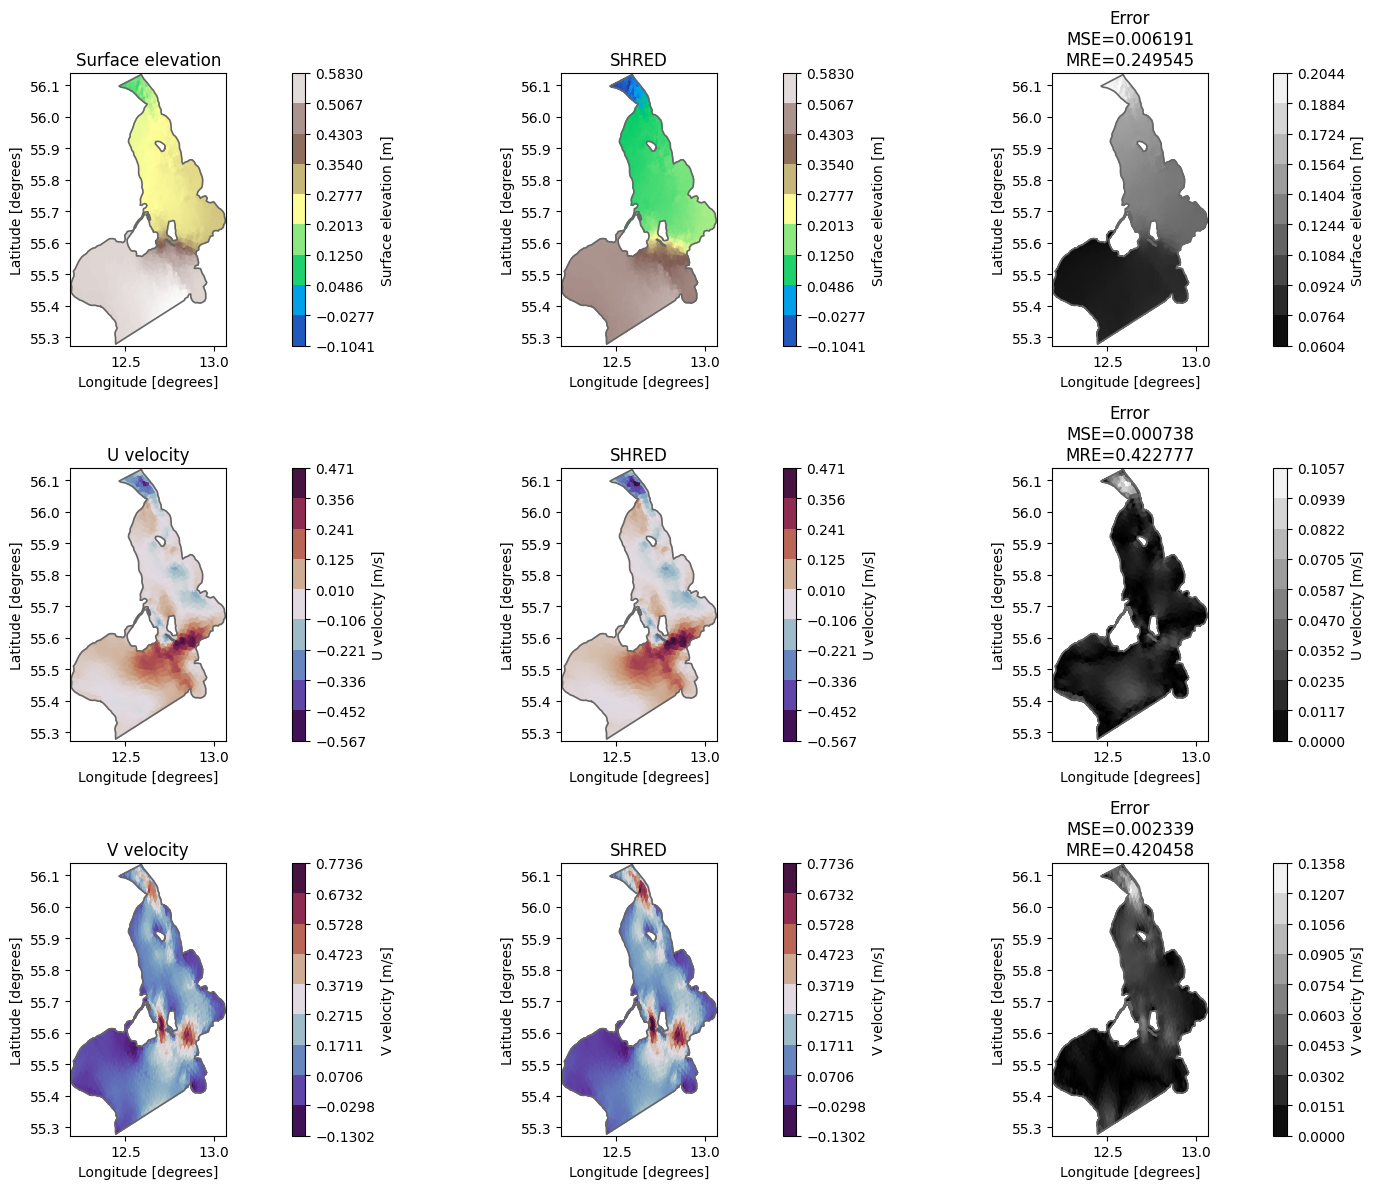

In [27]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.3.D)_masking_MHSA")

del engine, test_reconstruction, ds_shred, ds_error, mshred, model_args, train_errors, valid_errors, test_error

## (T.3.E): Masking x2 channels + MHSA

Starting training...


Training:  55%|█████▌    | 110/200 [11:16<09:13,  6.15s/it, Train Loss=0.00351, Val Loss=0.00356, Patience=39, Best Val Loss=0.00345, LR=2.07e-04]

Early stopping at epoch 111
Training completed with best validation loss: 0.0034


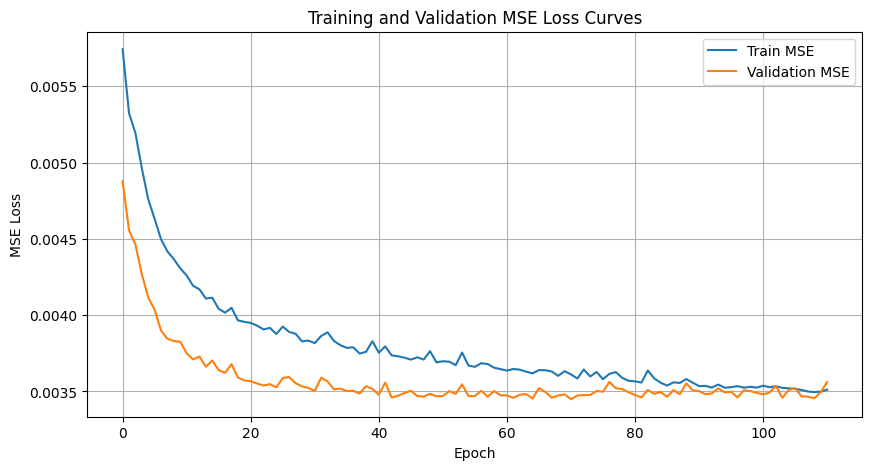

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003699,0.003455,0.004770,0.141250,0.138557,0.155077
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003608,0.003485,0.004753,0.139722,0.138935,0.154002
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003727,0.003432,0.004701,0.141552,0.138023,0.153497
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.003760,0.003452,0.004753,0.142187,0.138509,0.155241
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.003722,0.003510,0.004759,0.141516,0.139357,0.155506
5,(mSHRED): TR+cnn,(T.3.A): masking,0.003545,0.003419,0.004736,0.138358,0.137742,0.153346
6,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.003678,0.003448,0.004570,0.140781,0.138353,0.151570
7,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.003545,0.003431,0.004685,0.138363,0.137871,0.153344
8,(mSHRED): TR+cnn,(T.3.D): masking MHSA,0.003643,0.003420,0.004722,0.140272,0.137726,0.152767
9,(mSHRED): TR+cnn,(T.3.E): masking x2 channels + MHSA,0.003612,0.003449,0.004771,0.139582,0.138183,0.154261


In [28]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.E): masking x2 channels + MHSA", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/ORESUND/outputs/shred_(T.3.E)_masking_x2_channels_MHSA.png


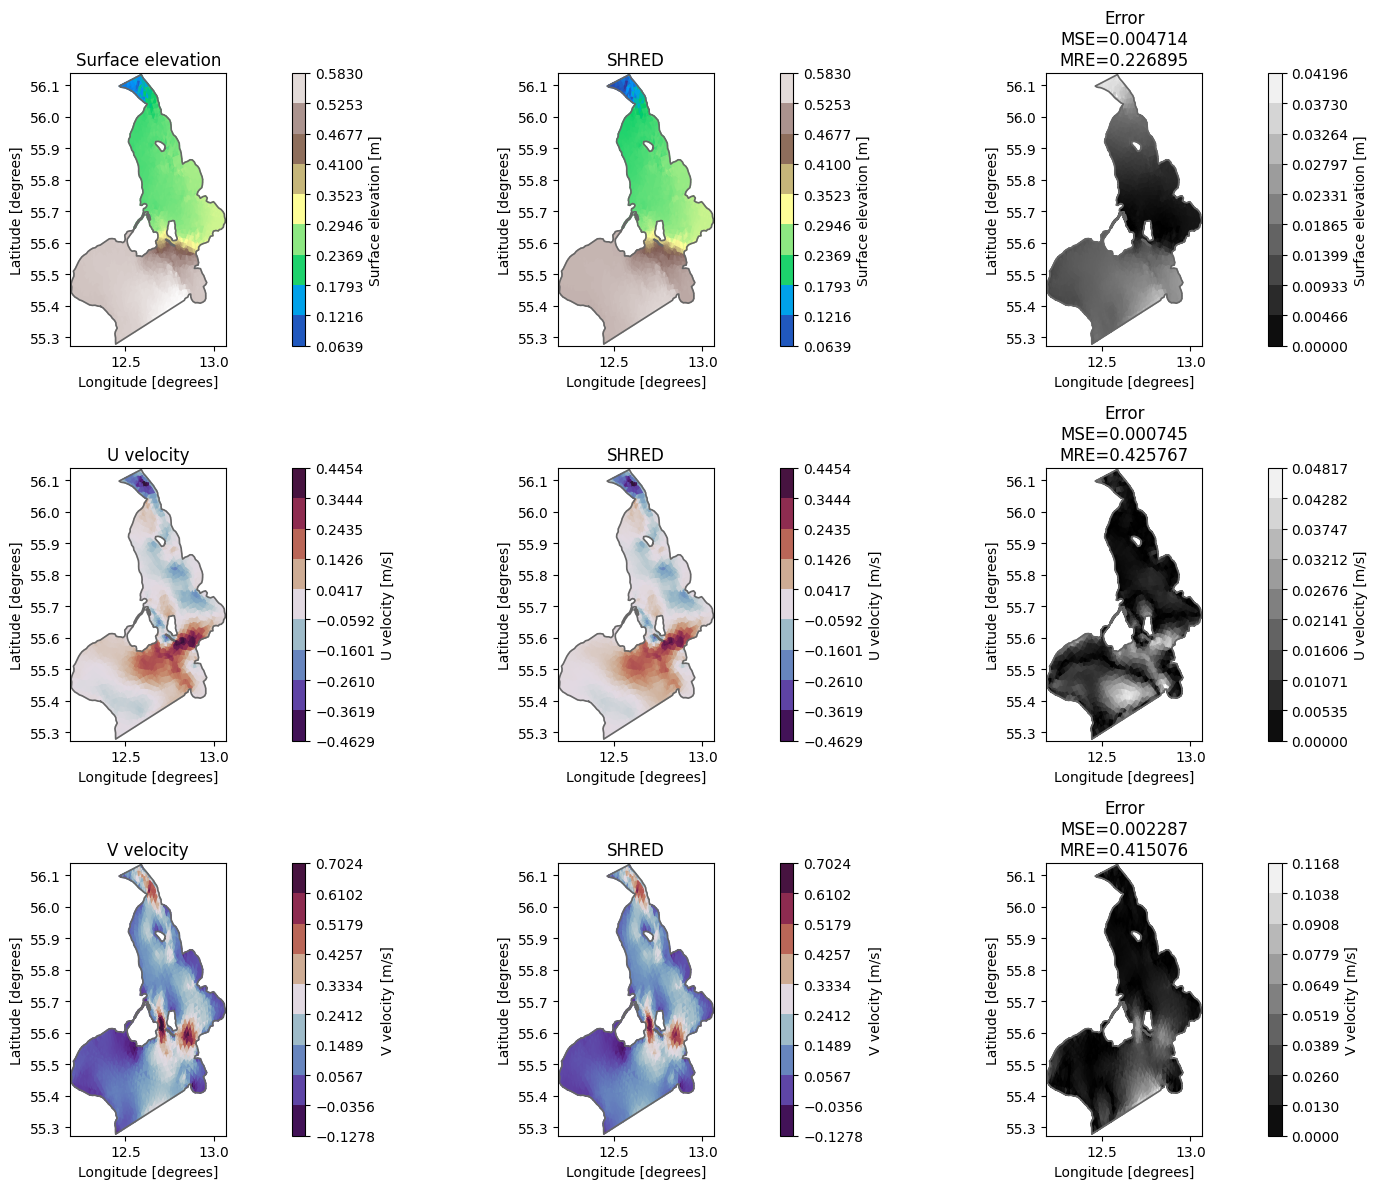

In [29]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.3.E)_masking_x2_channels_MHSA")

del engine, test_reconstruction, ds_shred, ds_error, mshred, model_args, train_errors, valid_errors, test_error

## (T.3.F): Masking MHSA learned

Starting training...


Training:  55%|█████▌    | 110/200 [16:19<13:21,  8.90s/it, Train Loss=0.00355, Val Loss=0.00348, Patience=39, Best Val Loss=0.00343, LR=2.07e-04]

Early stopping at epoch 111
Training completed with best validation loss: 0.0034


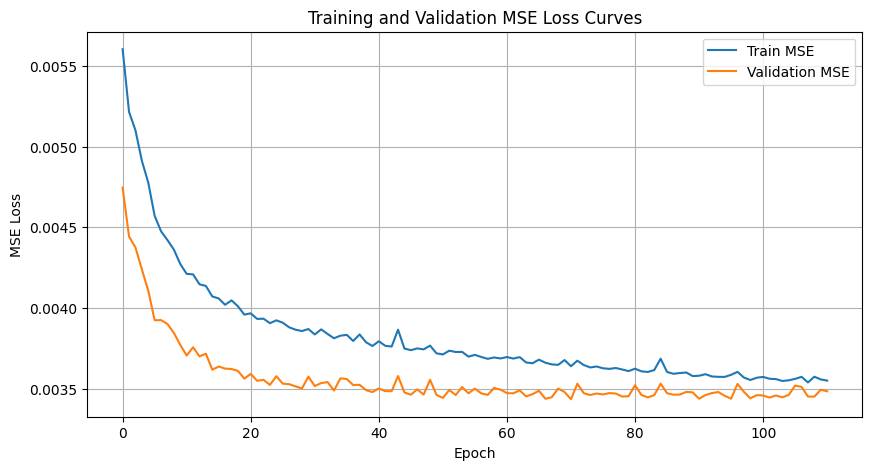

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003699,0.003455,0.004770,0.141250,0.138557,0.155077
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003608,0.003485,0.004753,0.139722,0.138935,0.154002
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003727,0.003432,0.004701,0.141552,0.138023,0.153497
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.003760,0.003452,0.004753,0.142187,0.138509,0.155241
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.003722,0.003510,0.004759,0.141516,0.139357,0.155506
5,(mSHRED): TR+cnn,(T.3.A): masking,0.003545,0.003419,0.004736,0.138358,0.137742,0.153346
6,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.003678,0.003448,0.004570,0.140781,0.138353,0.151570
7,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.003545,0.003431,0.004685,0.138363,0.137871,0.153344
8,(mSHRED): TR+cnn,(T.3.D): masking MHSA,0.003643,0.003420,0.004722,0.140272,0.137726,0.152767
9,(mSHRED): TR+cnn,(T.3.E): masking x2 channels + MHSA,0.003612,0.003449,0.004771,0.139582,0.138183,0.154261


In [30]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.F): masking MHSA learned", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/ORESUND/outputs/shred_(T.3.F)_masking_MHSA_learned.png


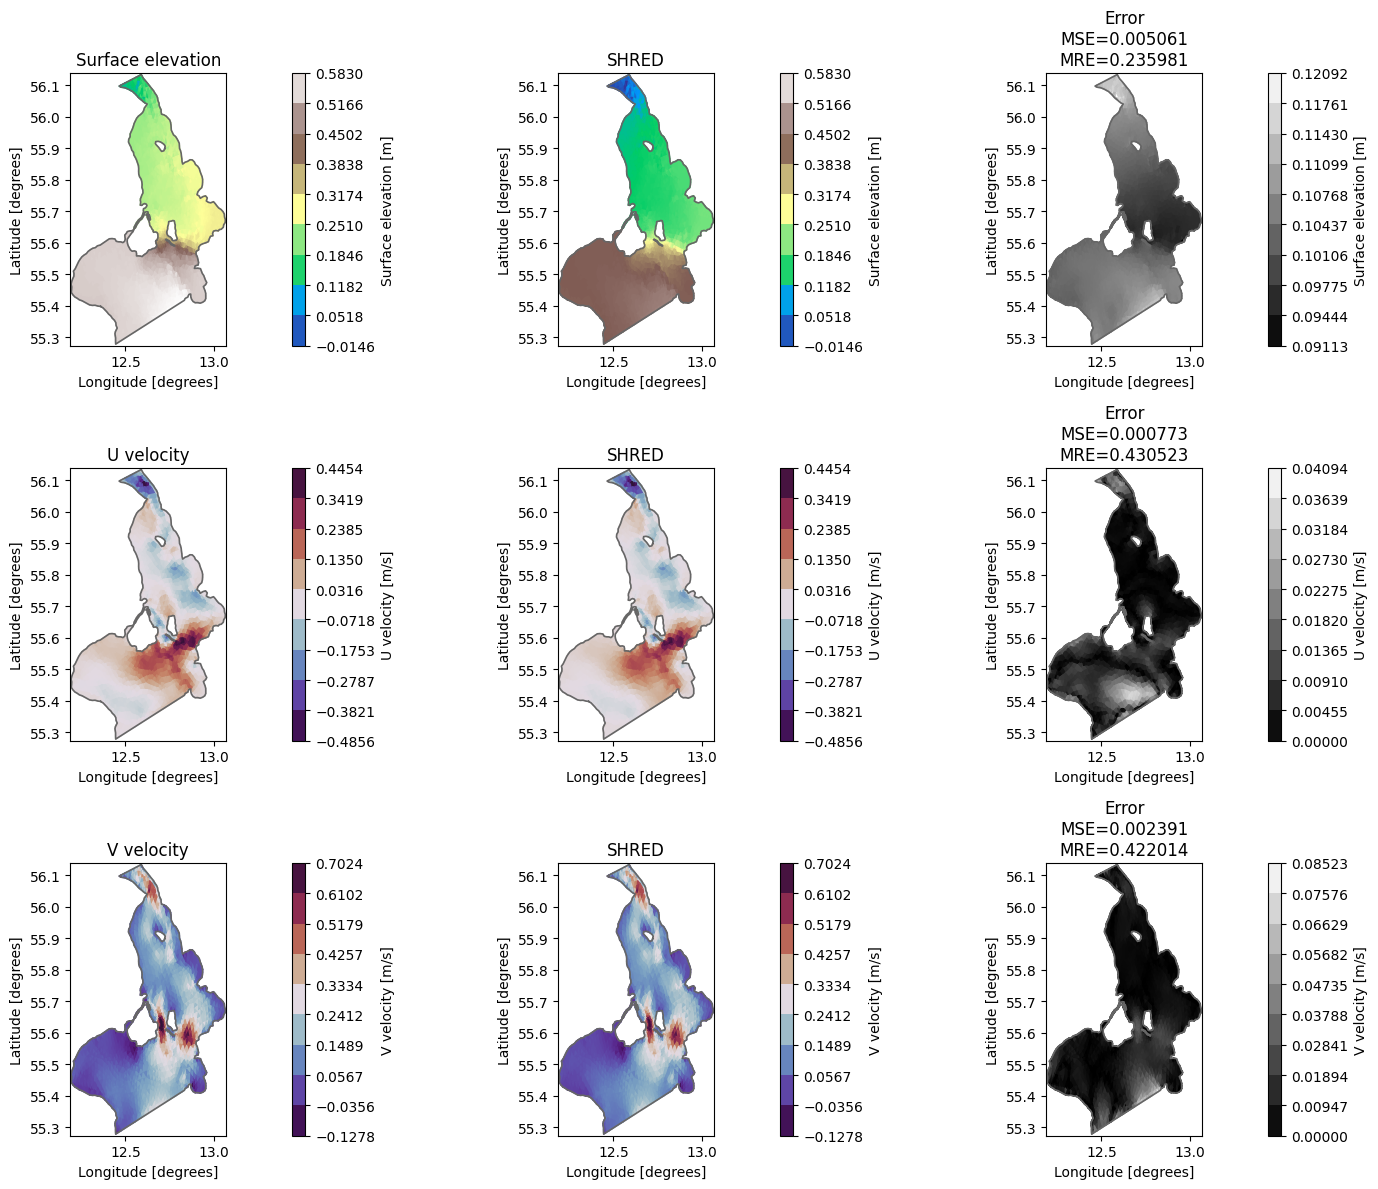

In [31]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.3.F)_masking_MHSA_learned")

del engine, test_reconstruction, ds_shred, ds_error, mshred, model_args, train_errors, valid_errors, test_error

## (T.3.G): Masking x2 channels + MHSA learned

Starting training...


Training:  64%|██████▍   | 128/200 [22:17<12:32, 10.45s/it, Train Loss=0.00349, Val Loss=0.00351, Patience=39, Best Val Loss=0.00344, LR=1.40e-04]

Early stopping at epoch 129
Training completed with best validation loss: 0.0034


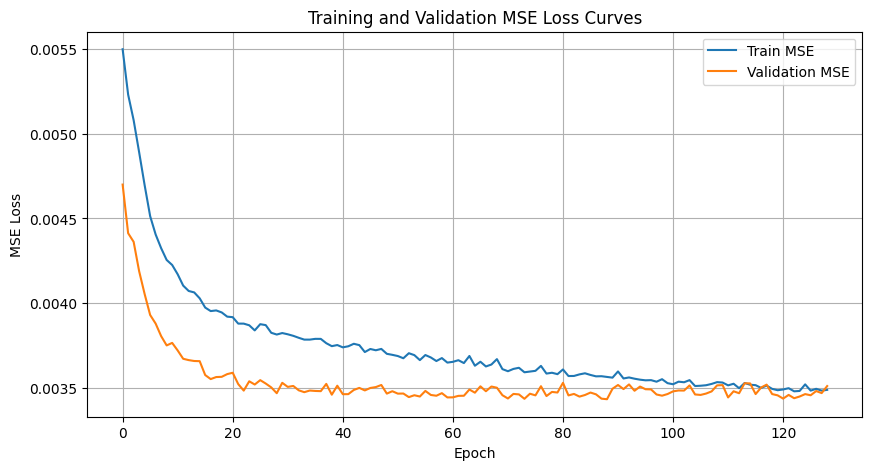

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003699,0.003455,0.004770,0.141250,0.138557,0.155077
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003608,0.003485,0.004753,0.139722,0.138935,0.154002
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003727,0.003432,0.004701,0.141552,0.138023,0.153497
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.003760,0.003452,0.004753,0.142187,0.138509,0.155241
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.003722,0.003510,0.004759,0.141516,0.139357,0.155506
5,(mSHRED): TR+cnn,(T.3.A): masking,0.003545,0.003419,0.004736,0.138358,0.137742,0.153346
6,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.003678,0.003448,0.004570,0.140781,0.138353,0.151570
7,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.003545,0.003431,0.004685,0.138363,0.137871,0.153344
8,(mSHRED): TR+cnn,(T.3.D): masking MHSA,0.003643,0.003420,0.004722,0.140272,0.137726,0.152767
9,(mSHRED): TR+cnn,(T.3.E): masking x2 channels + MHSA,0.003612,0.003449,0.004771,0.139582,0.138183,0.154261


In [32]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.G): masking x2 channels + MHSA learned", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/ORESUND/outputs/shred_(T.3.G)_masking_x2_channels_MHSA_learned.png


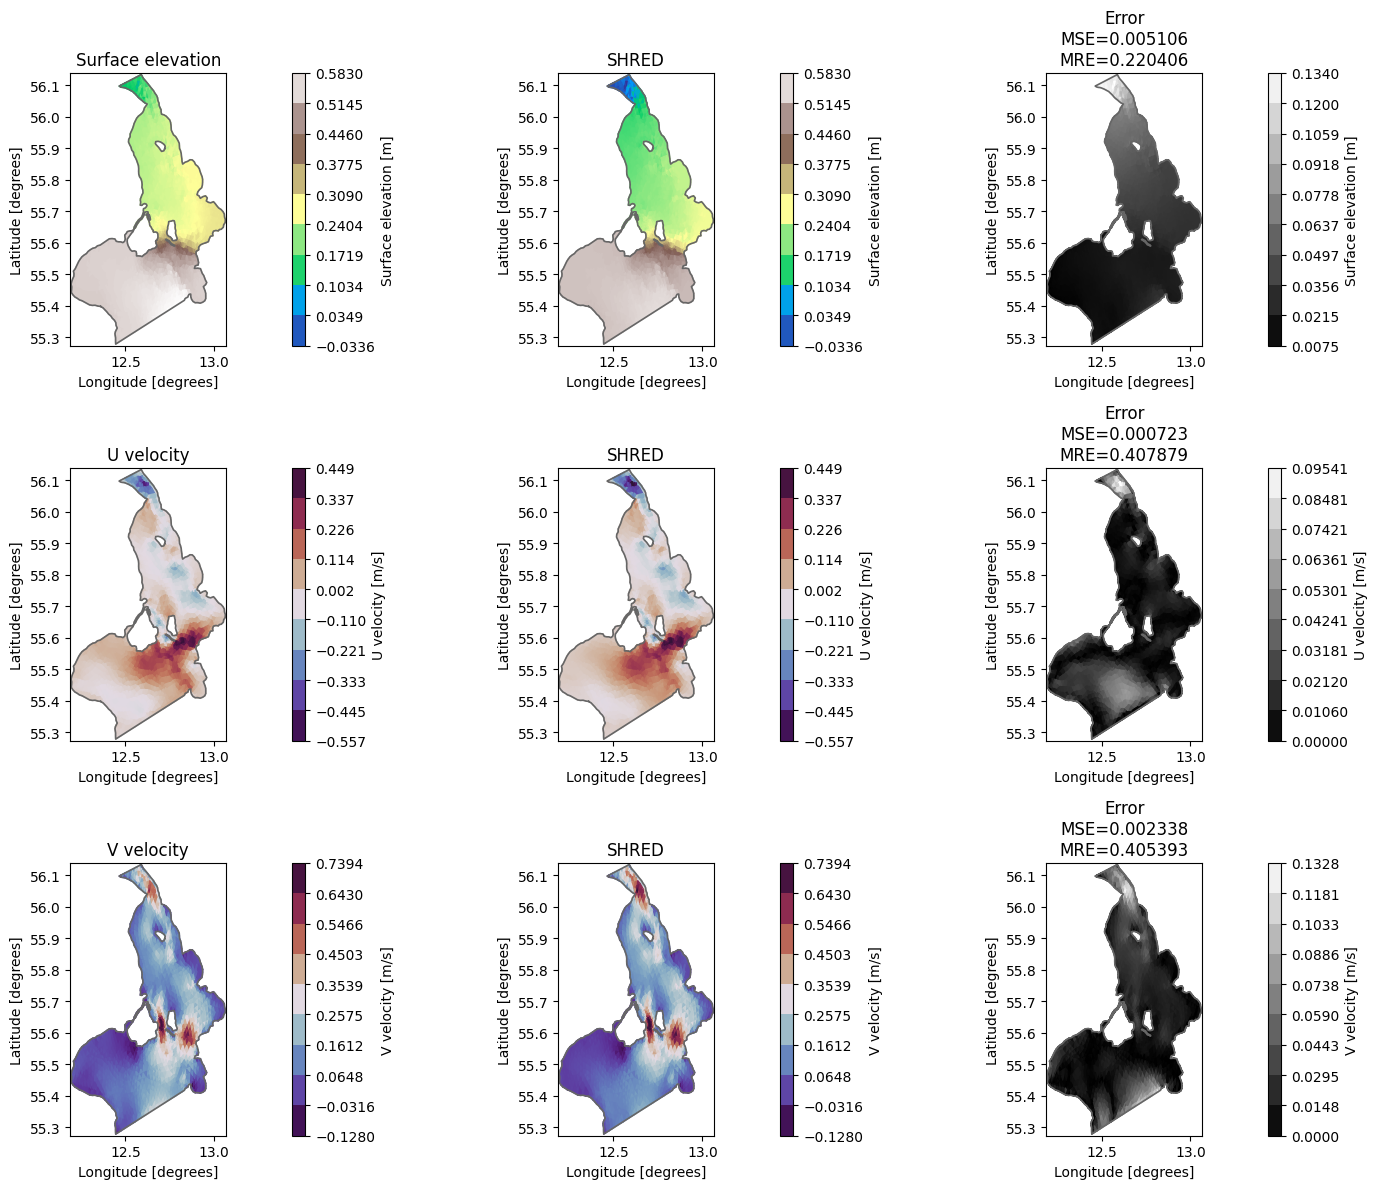

In [33]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)
ds_shred, ds_error = plot_shred_reconstruction(test_reconstruction, ds, geom, title_suffix="(T.3.G)_masking_x2_channels_MHSA_learned")

del engine, test_reconstruction, ds_shred, ds_error, mshred, manager, train_dataset, val_dataset, test_dataset, model_args, train_errors, valid_errors, test_error, nn_input_shape, nn_output_shape

## Results

In [34]:
dataframe_errors = pd.read_csv("dataframe_errors.csv")  # reload to ensure clean data
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.003699,0.003455,0.004770,0.141250,0.138557,0.155077
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.003608,0.003485,0.004753,0.139722,0.138935,0.154002
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.003727,0.003432,0.004701,0.141552,0.138023,0.153497
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.003760,0.003452,0.004753,0.142187,0.138509,0.155241
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.003722,0.003510,0.004759,0.141516,0.139357,0.155506
5,(mSHRED): TR+cnn,(T.3.A): masking,0.003545,0.003419,0.004736,0.138358,0.137742,0.153346
6,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.003678,0.003448,0.004570,0.140781,0.138353,0.151570
7,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.003545,0.003431,0.004685,0.138363,0.137871,0.153344
8,(mSHRED): TR+cnn,(T.3.D): masking MHSA,0.003643,0.003420,0.004722,0.140272,0.137726,0.152767
9,(mSHRED): TR+cnn,(T.3.E): masking x2 channels + MHSA,0.003612,0.003449,0.004771,0.139582,0.138183,0.154261


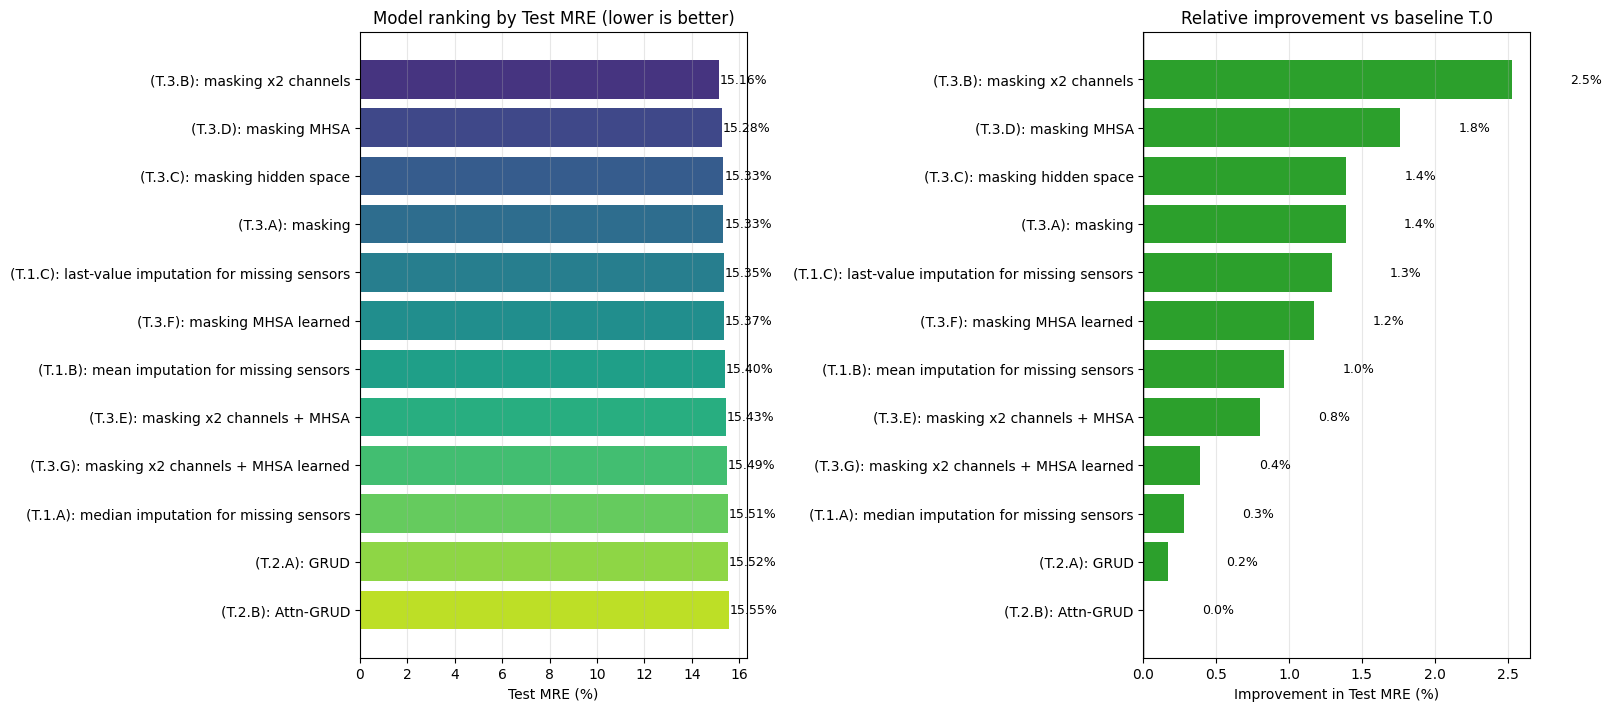

In [35]:
# Meaningful summary plot: ranking + improvement vs baseline
df_plot = dataframe_errors.sort_values("test-mre").reset_index(drop=True)

# Baseline = T.0 (only available sensors)
baseline_mask = df_plot["type"].str.contains("T.0", regex=False)
baseline_test_mre = df_plot.loc[baseline_mask, "test-mre"].iloc[0] if baseline_mask.any() else df_plot["test-mre"].max()

# Keep raw values for ratio math, but plot MRE on a 0-100% scale
df_plot["test-mre_%"] = 100 * df_plot["test-mre"]
df_plot["improvement_vs_T0_%"] = 100 * (baseline_test_mre - df_plot["test-mre"]) / baseline_test_mre

fig, axes = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)

# --- Left: Test MRE ranking (%) ---
colors = plt.cm.viridis(np.linspace(0.15, 0.9, len(df_plot)))
axes[0].barh(df_plot["type"], df_plot["test-mre_%"], color=colors)
axes[0].invert_yaxis()
axes[0].set_title("Model ranking by Test MRE (lower is better)")
axes[0].set_xlabel("Test MRE (%)")
axes[0].grid(axis="x", alpha=0.3)

for i, v in enumerate(df_plot["test-mre_%"]):
    axes[0].text(v + 0.03, i, f"{v:.2f}%", va="center", fontsize=9)

# --- Right: Improvement vs baseline (T.0) ---
imp_colors = ["tab:green" if x >= 0 else "tab:red" for x in df_plot["improvement_vs_T0_%"]]
axes[1].barh(df_plot["type"], df_plot["improvement_vs_T0_%"], color=imp_colors)
axes[1].invert_yaxis()
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_title("Relative improvement vs baseline T.0")
axes[1].set_xlabel("Improvement in Test MRE (%)")
axes[1].grid(axis="x", alpha=0.3)

for i, v in enumerate(df_plot["improvement_vs_T0_%"]):
    axes[1].text(v + (0.4 if v >= 0 else -2.5), i, f"{v:.1f}%", va="center", fontsize=9)

plt.show()

## run1


<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>model</th>
      <th>type</th>
      <th>train-mse</th>
      <th>val-mse</th>
      <th>test-mse</th>
      <th>train-mre</th>
      <th>val-mre</th>
      <th>test-mre</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.1.A): median imputation for missing sensors</td>
      <td>0.003699</td>
      <td>0.003455</td>
      <td>0.004770</td>
      <td>0.141250</td>
      <td>0.138557</td>
      <td>0.155077</td>
    </tr>
    <tr>
      <th>1</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.1.B): mean imputation for missing sensors</td>
      <td>0.003608</td>
      <td>0.003485</td>
      <td>0.004753</td>
      <td>0.139722</td>
      <td>0.138935</td>
      <td>0.154002</td>
    </tr>
    <tr>
      <th>2</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.1.C): last-value imputation for missing sen...</td>
      <td>0.003727</td>
      <td>0.003432</td>
      <td>0.004701</td>
      <td>0.141552</td>
      <td>0.138023</td>
      <td>0.153497</td>
    </tr>
    <tr>
      <th>3</th>
      <td>(mSHRED): GRUD+cnn</td>
      <td>(T.2.A): GRUD</td>
      <td>0.003760</td>
      <td>0.003452</td>
      <td>0.004753</td>
      <td>0.142187</td>
      <td>0.138509</td>
      <td>0.155241</td>
    </tr>
    <tr>
      <th>4</th>
      <td>(mSHRED): Attn-GRUD+cnn</td>
      <td>(T.2.B): Attn-GRUD</td>
      <td>0.003722</td>
      <td>0.003510</td>
      <td>0.004759</td>
      <td>0.141516</td>
      <td>0.139357</td>
      <td>0.155506</td>
    </tr>
    <tr>
      <th>5</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.A): masking</td>
      <td>0.003545</td>
      <td>0.003419</td>
      <td>0.004736</td>
      <td>0.138358</td>
      <td>0.137742</td>
      <td>0.153346</td>
    </tr>
    <tr>
      <th>6</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.B): masking x2 channels</td>
      <td>0.003678</td>
      <td>0.003448</td>
      <td>0.004570</td>
      <td>0.140781</td>
      <td>0.138353</td>
      <td>0.151570</td>
    </tr>
    <tr>
      <th>7</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.C): masking hidden space</td>
      <td>0.003545</td>
      <td>0.003431</td>
      <td>0.004685</td>
      <td>0.138363</td>
      <td>0.137871</td>
      <td>0.153344</td>
    </tr>
    <tr>
      <th>8</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.D): masking MHSA</td>
      <td>0.003643</td>
      <td>0.003420</td>
      <td>0.004722</td>
      <td>0.140272</td>
      <td>0.137726</td>
      <td>0.152767</td>
    </tr>
    <tr>
      <th>9</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.E): masking x2 channels + MHSA</td>
      <td>0.003612</td>
      <td>0.003449</td>
      <td>0.004771</td>
      <td>0.139582</td>
      <td>0.138183</td>
      <td>0.154261</td>
    </tr>
    <tr>
      <th>10</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.F): masking MHSA learned</td>
      <td>0.003639</td>
      <td>0.003435</td>
      <td>0.004736</td>
      <td>0.140116</td>
      <td>0.138000</td>
      <td>0.153686</td>
    </tr>
    <tr>
      <th>11</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.G): masking x2 channels + MHSA learned</td>
      <td>0.003567</td>
      <td>0.003436</td>
      <td>0.004781</td>
      <td>0.138814</td>
      <td>0.138025</td>
      <td>0.154897</td>
    </tr>
  </tbody>
</table>
</div>

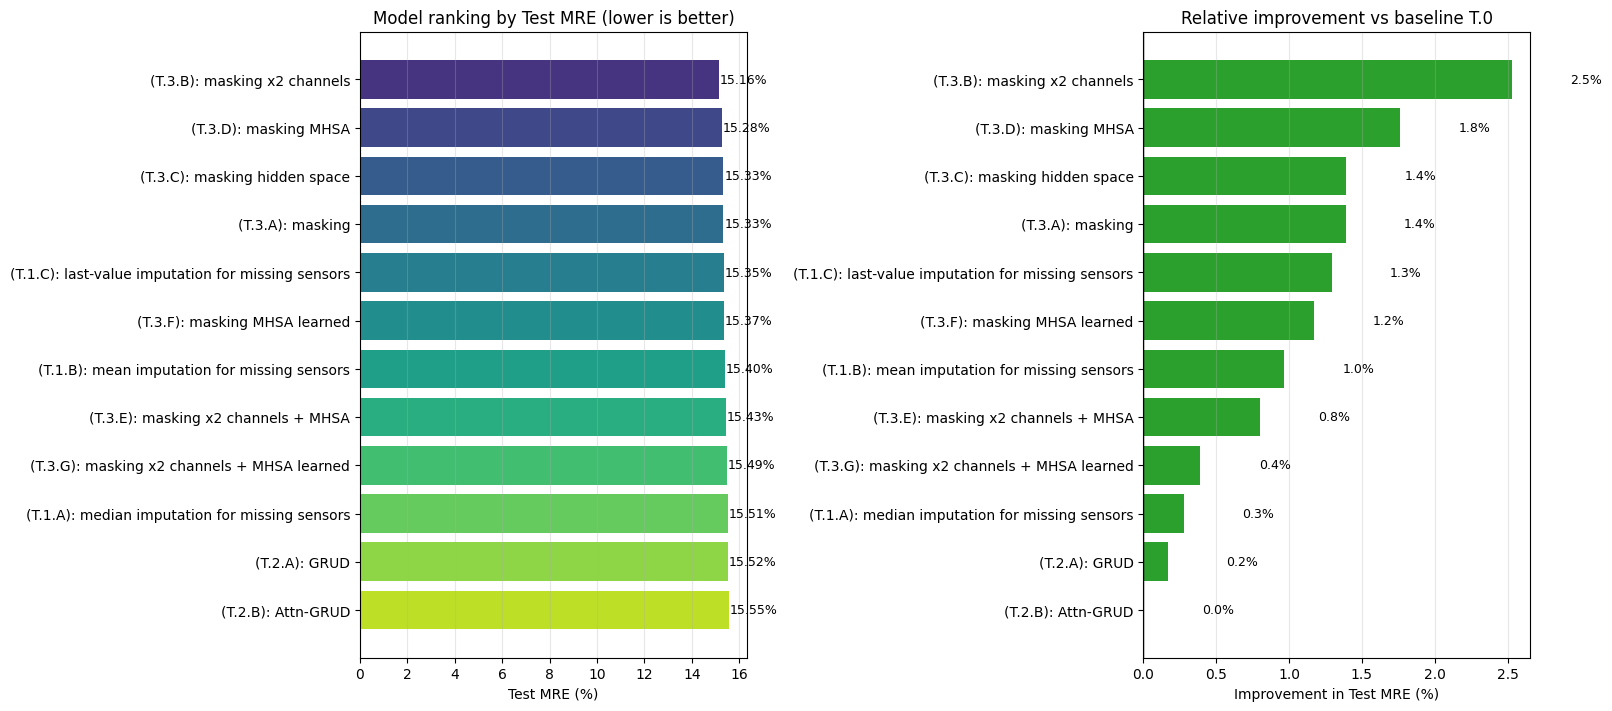